# Emotion Detection — Machine Learning Project
**CA-4 Use Case Based Continuous Assessment — Classification Case Study**

## Project Objective
The objective is to **detect the emotion expressed in a short English text** and classify it into one of six classes: **sadness, joy, love, anger, fear and surprise**. Such a model can be used to monitor customer feedback, prioritise support tickets, track brand sentiment on social media or make chatbots respond with more empathy.

## Project Workflow (as required by the CA-4 document)
| Week | Activities |
|---|---|
| Week 1 | Problem understanding, data download, EDA (missing values, outliers, distributions, correlation), feature encoding, 70:30 split |
| Week 1 (Baseline) | Logistic Regression, Decision Tree, KNN — Accuracy, Precision, Recall, F1 Score, Confusion Matrix, comparison table, interpretation |
| Week 2 | Random Forest, Gradient Boosting / XGBoost, GridSearchCV, cross-validation, ROC curve, AUC score, class-imbalance handling (class weights) |
| Week 4 | Final model justification, feature-importance explanation, business insights, limitations, future improvements |

## Methodology
- Target variable: `emotion` (6 classes)
- Problem type: **Supervised Multi-class Classification** (text classification)
- Text representation: **TF-IDF** (unigrams + bigrams), fitted **inside a Pipeline** so that no information from the test set leaks into training
- Train-test split: **70 % train / 30 % test** (stratified, so every emotion keeps the same share in both parts)
- Evaluation metrics: **Accuracy, Precision, Recall, F1 Score, Confusion Matrix, ROC curve and AUC** (Precision / Recall / F1 are *macro-averaged* so that rare emotions count as much as frequent ones)
- Validation: **5-fold stratified cross-validation** (on the training data only)
- Hyper-parameter tuning: **GridSearchCV**
- Class imbalance: handled with **class weights**
- Model selection is done with the **cross-validated macro-F1**. The test set is **never used for tuning or model selection**; it is only used to report the final performance.

---
# WEEK 1 — Problem Understanding & Data Exploration

## 1.1 Business / scientific problem
People express feelings in free text — reviews, tweets, chat messages, emails. Reading all of them by hand is impossible at scale. An **emotion detection** model reads a sentence and tells *which* emotion it carries, so that a business can **(a)** measure how customers feel, **(b)** route angry or fearful messages to a human agent quickly and **(c)** react to the emotions that matter most.

* **Problem type:** supervised **multi-class classification** (the target `emotion` has six categories).
* **Target variable:** `emotion` — sadness, joy, love, anger, fear, surprise.
* **Why regression is not used:** the target is categorical, so regression models and metrics (MAE, RMSE, R², residual analysis) are *not applicable*.
* **Why macro-averaged metrics:** the emotions are not equally frequent. Accuracy alone can look good even if a rare emotion is never predicted, so macro Precision / Recall / F1 are reported next to accuracy.

## 1.2 Dataset source (official)
**Emotions dataset for NLP** — Kaggle dataset by *Praveen Govi*, https://www.kaggle.com/datasets/praveengovi/emotions-dataset (the dataset page is titled *"Emotions dataset for NLP"*). It is distributed as three text files (`train.txt`, `val.txt`, `test.txt`), one sentence per line in the format `text;emotion`. As the CA-4 document asks for a fresh **70 : 30** split, the three files are **combined** and split again below.

| Column | Meaning |
|---|---|
| `text` | a short English sentence in which a person describes a feeling |
| `emotion` | the emotion expressed by the sentence — **target** (sadness, joy, love, anger, fear, surprise) |

In [1]:
!pip install -q xgboost kagglehub scipy

In [2]:
# ---------------------------------------------------------------
# Imports, global settings and helper functions
# ---------------------------------------------------------------
import os, glob, random, textwrap, warnings
warnings.filterwarnings("ignore")

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Machine learning
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, auc, roc_auc_score)
from xgboost import XGBClassifier
import joblib

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
sns.set_theme(style="whitegrid")

# Folder where every figure is stored (useful for the 6-8 page report)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Save the current matplotlib figure to figures/<name>.png and show it.
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

def say(text, width=110):
    # Print a wrapped paragraph (used for the auto-generated interpretations).
    print(textwrap.fill(text, width=width))

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ---------------------------------------------------------------
# Locate / download the dataset
#   1) already uploaded to Colab (or a local folder)
#   2) automatic download from the official Kaggle source (kagglehub)
#   3) manual upload through the Colab file picker
# The files have no header: every line is  "<text>;<emotion>"
# ---------------------------------------------------------------
EMOTIONS = {"sadness", "joy", "love", "anger", "fear", "surprise"}

def try_read(path, nrows=None):
    # Return a DataFrame with the columns ['text', 'emotion'] if the file is an emotion file, else None.
    attempts = [
        lambda: pd.read_csv(path, sep=";", header=None, names=["text", "emotion"],
                            nrows=nrows, on_bad_lines="skip", encoding="utf-8"),
        lambda: pd.read_csv(path, nrows=nrows, encoding="utf-8"),
    ]
    for attempt in attempts:
        try:
            df = attempt()
        except Exception:
            continue
        df.columns = [str(c).strip().lower() for c in df.columns]
        if "label" in df.columns and "emotion" not in df.columns:
            df = df.rename(columns={"label": "emotion"})
        if not {"text", "emotion"}.issubset(df.columns):
            continue
        df = df[["text", "emotion"]].copy()
        df["emotion"] = df["emotion"].astype("string").str.strip().str.lower()
        labels = set(df["emotion"].dropna().unique())
        if len(labels) > 0 and labels.issubset(EMOTIONS) and df["emotion"].notna().mean() > 0.5:
            return df
    return None

def find_dataset_files(search_dirs):
    for folder in search_dirs:
        hits = []
        for path in sorted(glob.glob(os.path.join(folder, "**", "*"), recursive=True)):
            if (os.path.isfile(path) and path.lower().endswith((".txt", ".csv"))
                    and FIG_DIR not in path.split(os.sep) and try_read(path, nrows=200) is not None):
                hits.append(path)
        if hits:
            return hits
    return []

LOCAL_DIRS = ["/content", "/content/data", "/data", "data", "/kaggle/input", "."]
DATA_FILES = find_dataset_files(LOCAL_DIRS)

if not DATA_FILES:
    try:
        import kagglehub
        for slug in ["praveengovi/emotions-dataset-for-nlp", "praveengovi/emotions-dataset"]:
            try:
                download_dir = kagglehub.dataset_download(slug)
                DATA_FILES = find_dataset_files([download_dir])
                if DATA_FILES:
                    break
            except Exception as err:
                print(f"Download of '{slug}' was not possible:", err)
    except Exception as err:
        print("kagglehub is not available:", err)

if not DATA_FILES:
    try:
        from google.colab import files
        print("Please upload train.txt, val.txt and test.txt (download them from the Kaggle link above).")
        uploaded = files.upload()
        DATA_FILES = [name for name in uploaded if try_read(name, nrows=200) is not None]
    except Exception:
        pass

if not DATA_FILES:
    raise FileNotFoundError(
        "Dataset not found. Download train.txt, val.txt and test.txt from "
        "https://www.kaggle.com/datasets/praveengovi/emotions-dataset "
        "and upload them to /content (Colab: left sidebar -> Files -> upload)."
    )

print("Dataset files found:")
for path in DATA_FILES:
    print("  ", path)

Using Colab cache for faster access to the 'emotions-dataset-for-nlp' dataset.
Dataset files found:
   /kaggle/input/emotions-dataset-for-nlp/test.txt
   /kaggle/input/emotions-dataset-for-nlp/train.txt
   /kaggle/input/emotions-dataset-for-nlp/val.txt


In [4]:
# Load and combine the dataset files (the CA-4 document asks for a new 70:30 split of the whole dataset)
raw_parts = []
for path in DATA_FILES:
    part = try_read(path)
    part["source_file"] = os.path.basename(path)
    raw_parts.append(part)
raw = pd.concat(raw_parts, ignore_index=True)

print("DATASET LOADED SUCCESSFULLY!")
print("Rows read from every file:")
display(raw["source_file"].value_counts().rename("rows").to_frame())

data = raw[["text", "emotion"]].copy()
data["text"] = data["text"].astype(object).str.strip()      # plain Python strings (missing values stay missing)
data["emotion"] = data["emotion"].astype(object)
print("Combined shape:", data.shape)
display(data.sample(8, random_state=SEED))

DATASET LOADED SUCCESSFULLY!
Rows read from every file:


,rows
source_file,
train.txt,16000
test.txt,2000
val.txt,2000


Combined shape: (20000, 2)


,text,emotion
10650,i feel assured that foods that are grown organ...,joy
2041,i already have my christmas trees up i got two...,joy
8668,i feel all betrayed and disillusioned,sadness
1114,i will tell you that i am feeling quite invigo...,joy
13902,i start to feel less exhausted the bits and pi...,sadness
11963,i was listening to belle and sebastian feeling...,fear
11072,i be able to look them in the face again witho...,sadness
3002,i am thankful for feeling useful,joy


In [5]:
print("DATASET INFORMATION")
data.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text     20000 non-null  object
 1   emotion  20000 non-null  object
dtypes: object(2)
memory usage: 312.6+ KB


## 1.3 Dataset description — size, feature types and target variable

In [6]:
# ---------------------------------------------------------------
# Dataset size, feature types and target variable
# ---------------------------------------------------------------
print("DATASET SIZE")
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])

feature_info = {
    "text":    ("Text - free-form English sentence", "Feature", "Short sentence in which a person describes a feeling"),
    "emotion": ("Categorical - nominal (6 classes)", "TARGET",  "Emotion expressed: sadness, joy, love, anger, fear, surprise"),
}

feature_types = pd.DataFrame({
    "Column":       data.columns,
    "Data type":    [str(t) for t in data.dtypes],
    "Feature type": [feature_info.get(c, ("-", "-", "-"))[0] for c in data.columns],
    "Role":         [feature_info.get(c, ("-", "-", "-"))[1] for c in data.columns],
    "Description":  [feature_info.get(c, ("-", "-", "-"))[2] for c in data.columns],
})
print("\nFEATURE TYPES")
display(feature_types)

print("\nTARGET VARIABLE: emotion")
display(data["emotion"].value_counts(dropna=False).rename("Count").to_frame())

DATASET SIZE
Rows    : 20000
Columns : 2

FEATURE TYPES


,Column,Data type,Feature type,Role,Description
0,text,object,Text - free-form English sentence,Feature,Short sentence in which a person describes a f...
1,emotion,object,Categorical - nominal (6 classes),TARGET,"Emotion expressed: sadness, joy, love, anger, ..."



TARGET VARIABLE: emotion


,Count
emotion,
joy,6761
sadness,5797
anger,2709
fear,2373
love,1641
surprise,719


**Feature-type explanation**

* **Text:** `text` is the only input. Machine-learning models need numbers, so the text is converted to **TF-IDF vectors** (see 1.7).
* **Categorical target:** `emotion` is a nominal variable with six classes (there is no natural order between them), so classification models and metrics are used.
* **Numerical / datetime columns:** there are none in the raw data. A few simple numeric descriptors of the text (word count, character count, average word length) are created below **for exploration only**.
* **Leakage check:** the model only sees the sentence itself; no column derived from the label is used as an input.

In [7]:
# ---------------------------------------------------------------
# Missing value analysis
# ---------------------------------------------------------------
print("MISSING VALUE ANALYSIS")
missing = pd.DataFrame({
    "Missing values": data.isnull().sum(),
    "Missing %": (data.isnull().mean() * 100).round(3),
})
display(missing)
print("Total missing values:", int(data.isnull().sum().sum()))
print("Empty text strings  :", int((data["text"].fillna("").str.len() == 0).sum()))

# Text cannot be imputed meaningfully, so rows with a missing/empty text or label are removed
before = len(data)
data = data.dropna(subset=["text", "emotion"])
data = data[data["text"].str.len() > 0].reset_index(drop=True)
print("Rows removed because of missing / empty values:", before - len(data))

MISSING VALUE ANALYSIS


,Missing values,Missing %
text,0,0.0
emotion,0,0.0


Total missing values: 0
Empty text strings  : 0
Rows removed because of missing / empty values: 0


In [8]:
# Check duplicate records and remove them
n_exact = int(data.duplicated().sum())
print("Exact duplicate records (same text AND same emotion):", n_exact)
data = data.drop_duplicates().reset_index(drop=True)

# The same sentence with two DIFFERENT emotions is ambiguous - the model cannot learn a rule from it, and it could
# end up in both the training and the test set, so such sentences are removed completely.
conflict_mask = data.duplicated(subset="text", keep=False)
print("Rows whose text appears with different emotions   :", int(conflict_mask.sum()))
data = data[~conflict_mask].reset_index(drop=True)

print("Dataset shape after cleaning:", data.shape)

Exact duplicate records (same text AND same emotion): 1
Rows whose text appears with different emotions   : 102
Dataset shape after cleaning: (19897, 2)


**Missing-value interpretation.** The table above shows the number and percentage of missing values in each column. Free text cannot be filled with a mean or median, so a row with a missing text or label would simply be dropped (the cell reports how many, if any). Exact duplicates were removed so that the same sentence cannot appear in both the training and the test set, and sentences that carry two different labels were removed because they are contradictory.

In [9]:
# Simple numeric descriptors of the text (used for exploration only - NOT given to the models)
data["word_count"]   = data["text"].str.split().str.len()
data["char_count"]   = data["text"].str.len()
data["avg_word_len"] = data["char_count"] / data["word_count"]

print("STATISTICAL DESCRIPTION OF THE TEXT DESCRIPTORS")
display(data[["word_count", "char_count", "avg_word_len"]].describe())

print("A FEW EXAMPLES OF EVERY EMOTION")
for emo in data["emotion"].value_counts().index:
    print(f"\n[{emo}]")
    for t in data.loc[data["emotion"] == emo, "text"].head(3):
        print("   -", t)

STATISTICAL DESCRIPTION OF THE TEXT DESCRIPTORS


,word_count,char_count,avg_word_len
count,19897.000000,19897.000000,19897.000000
mean,19.146354,96.730010,5.074693
std,10.980389,55.820666,0.564962
min,2.000000,7.000000,3.200000
25%,11.000000,53.000000,4.700000
50%,17.000000,86.000000,5.000000
75%,25.000000,129.000000,5.400000
max,66.000000,300.000000,9.777778


A FEW EXAMPLES OF EVERY EMOTION

[joy]
   - i left with my bouquet of red and yellow tulips under my arm feeling slightly more optimistic than when i arrived
   - i explain why i clung to a relationship with a boy who was in many ways immature and uncommitted despite the excitement i should have been feeling for getting accepted into the masters program at the university of virginia
   - i like to have the same breathless feeling as a reader eager to see what will happen next

[sadness]
   - im feeling rather rotten so im not very ambitious right now
   - im updating my blog because i feel shitty
   - i never make her separate from me because i don t ever want her to feel like i m ashamed with her

[anger]
   - i felt anger when at the end of a telephone call
   - i jest i feel grumpy tired and pre menstrual which i probably am but then again its only been a week and im about as fit as a walrus on vacation for the summer
   - i feel just bcoz a fight we get mad to each other n u wanna 

## 1.4 Distribution analysis

,Count,Percent
emotion,,
joy,6728,33.81
sadness,5790,29.10
anger,2700,13.57
fear,2358,11.85
love,1612,8.10
surprise,709,3.56


Imbalance ratio (largest / smallest class): 9.5 : 1


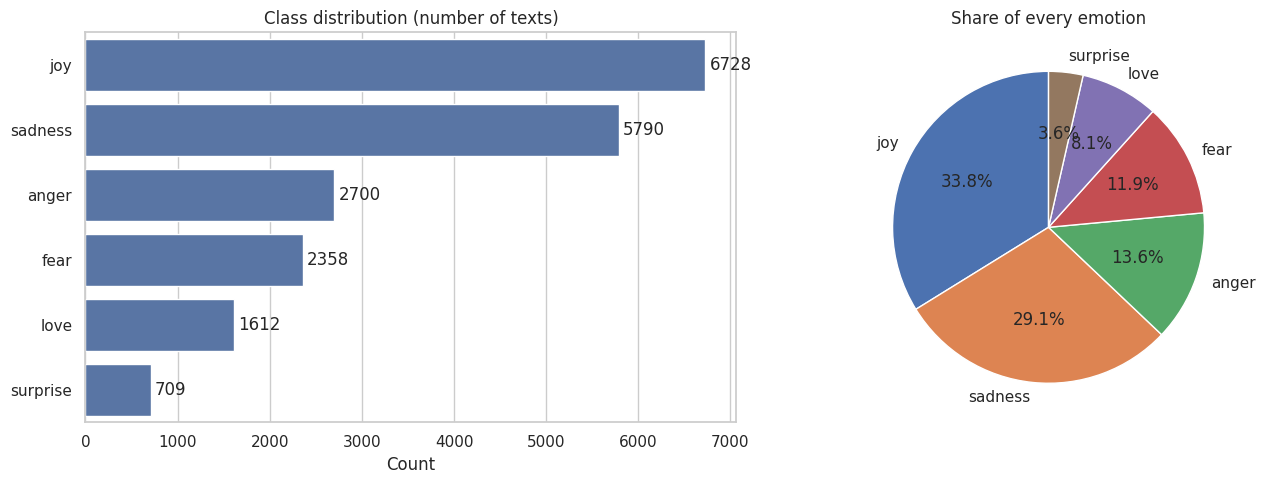

In [10]:
# ---------------------------------------------------------------
# Distribution of the TARGET (class balance)
# ---------------------------------------------------------------
class_counts = data["emotion"].value_counts()
class_table = pd.DataFrame({"Count": class_counts, "Percent": (class_counts / len(data) * 100).round(2)})
display(class_table)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (largest / smallest class): {imbalance_ratio:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=data, y="emotion", order=class_counts.index, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)
axes[0].set_title("Class distribution (number of texts)")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("")
axes[1].pie(class_counts.values, labels=class_counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Share of every emotion")
save_fig("01_class_distribution")

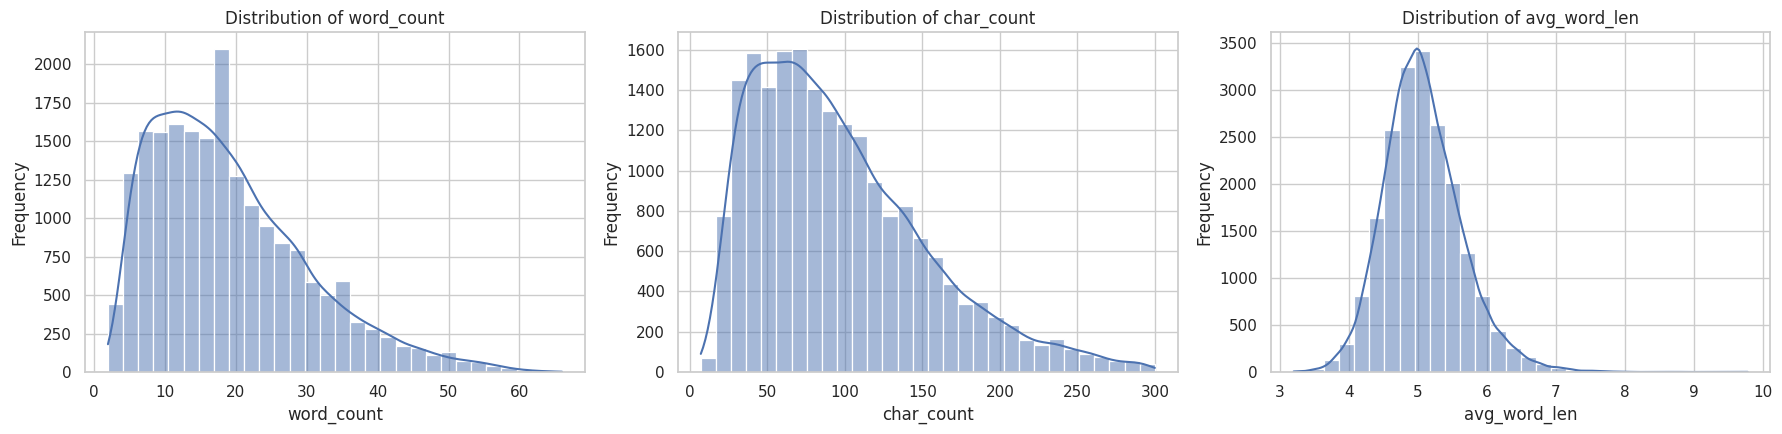

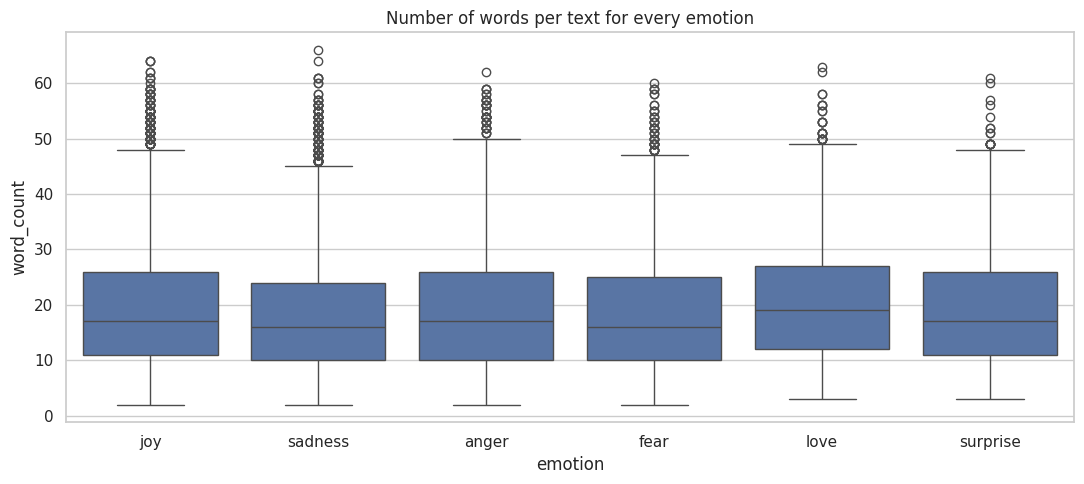

,Skewness,Kurtosis,Shapiro-Wilk p-value,Looks normal (p>0.05)?
word_count,0.953,0.663,0.0,No
char_count,0.957,0.609,0.0,No
avg_word_len,0.612,1.398,0.0,No


In [11]:
# ---------------------------------------------------------------
# Distribution of the text descriptors
# ---------------------------------------------------------------
num_cols = ["word_count", "char_count", "avg_word_len"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(data[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
save_fig("02_text_descriptor_distributions")

plt.figure(figsize=(11, 5))
sns.boxplot(data=data, x="emotion", y="word_count", order=class_counts.index)
plt.title("Number of words per text for every emotion")
save_fig("03_word_count_by_emotion")

# Skewness, kurtosis and a formal normality test (Shapiro-Wilk, on a sample of at most 5000 values)
dist_table = pd.DataFrame({
    "Skewness": data[num_cols].skew().round(3),
    "Kurtosis": data[num_cols].kurt().round(3),
    "Shapiro-Wilk p-value": [round(stats.shapiro(data[c].sample(min(5000, len(data)), random_state=SEED))[1], 4) for c in num_cols],
})
dist_table["Looks normal (p>0.05)?"] = np.where(dist_table["Shapiro-Wilk p-value"] > 0.05, "Yes", "No")
display(dist_table)

In [12]:
most_skewed = dist_table["Skewness"].abs().idxmax()
minority_name, majority_name = class_counts.idxmin(), class_counts.idxmax()
say(f"Interpretation (distributions): the target is IMBALANCED - '{majority_name}' is the largest class ({class_table.loc[majority_name, 'Percent']:.1f}%) "
    f"and '{minority_name}' the smallest ({class_table.loc[minority_name, 'Percent']:.1f}%), a ratio of {imbalance_ratio:.1f} : 1. "
    f"A model that ignores the rare emotions can still reach a high accuracy, which is why macro-averaged metrics and class weights are used later. "
    f"The typical text has {data['word_count'].median():.0f} words (mean {data['word_count'].mean():.1f}). "
    f"The most skewed descriptor is '{most_skewed}' (skewness = {dist_table.loc[most_skewed, 'Skewness']:.2f}); a positive value means a long right tail "
    f"(a few unusually long texts). The Shapiro-Wilk test (p < 0.05 = not normal) shows that the descriptors are not perfectly normal, "
    f"which does not matter here because the models do not assume normal inputs.")

Interpretation (distributions): the target is IMBALANCED - 'joy' is the largest class (33.8%) and 'surprise'
the smallest (3.6%), a ratio of 9.5 : 1. A model that ignores the rare emotions can still reach a high
accuracy, which is why macro-averaged metrics and class weights are used later. The typical text has 17 words
(mean 19.1). The most skewed descriptor is 'char_count' (skewness = 0.96); a positive value means a long right
tail (a few unusually long texts). The Shapiro-Wilk test (p < 0.05 = not normal) shows that the descriptors
are not perfectly normal, which does not matter here because the models do not assume normal inputs.


## 1.5 Outlier detection
For text data, an "outlier" is an unusually **long or short sentence**. The IQR rule and the Z-score rule are applied to the three text descriptors.

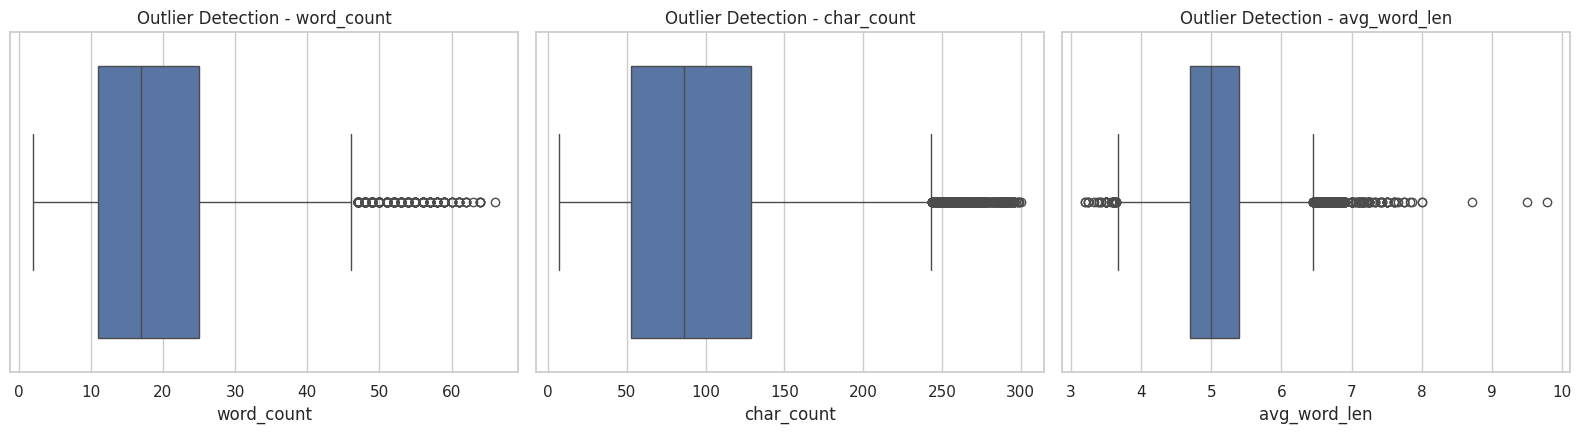

,Variable,Q1,Q3,Lower fence,Upper fence,Outliers (IQR rule),Outlier % (IQR),Outliers (|Z| > 3)
0,word_count,11.0,25.0,-10.00,46.00,467,2.35,181
1,char_count,53.0,129.0,-61.00,243.00,401,2.02,182
2,avg_word_len,4.7,5.4,3.65,6.45,406,2.04,154


The longest texts in the data set:
   - i guess which meant or so i assume no photos no words or no other way to convey what it really feels unless you feels it yourself or [...]
   - i lost my special mind but don t worry i m still sane i just wanted you to feel what i felt while reading this book i don t know how [...]
   - i feel you i dont believ in you but i keep my faithful to you god gives me a chance to feel what is apathetic after it but much [...]


In [13]:
plt.figure(figsize=(16, 4.5))
for i, col in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x=data[col])
    plt.title(f"Outlier Detection - {col}")
save_fig("04_boxplots")

# Quantify the outliers with the IQR rule and the Z-score rule
outlier_rows = []
for col in num_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((data[col] < low) | (data[col] > high)).sum())
    n_z = int((np.abs(stats.zscore(data[col])) > 3).sum())
    outlier_rows.append({
        "Variable": col, "Q1": round(q1, 3), "Q3": round(q3, 3),
        "Lower fence": round(low, 3), "Upper fence": round(high, 3),
        "Outliers (IQR rule)": n_iqr, "Outlier % (IQR)": round(100 * n_iqr / len(data), 2),
        "Outliers (|Z| > 3)": n_z,
    })
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

print("The longest texts in the data set:")
for t in data.sort_values("word_count", ascending=False)["text"].head(3):
    print("   -", textwrap.shorten(t, width=140))

In [14]:
n_out_total = int(outlier_table["Outliers (IQR rule)"].sum())
which = ", ".join(outlier_table.loc[outlier_table["Outliers (IQR rule)"] > 0, "Variable"]) or "none"
say(f"Interpretation (outliers) and decision: the IQR rule flags {n_out_total} outlying value(s) in total (descriptors affected: {which}). "
    f"These are genuine long or short sentences written by real people, not measurement errors, and a longer sentence may simply carry more emotional words. "
    f"Deleting them would remove valid examples (and could remove entire rare-emotion examples), so the outliers are KEPT. "
    f"TF-IDF normalises every text vector to unit length, which already removes most of the effect of very long or very short texts.")

Interpretation (outliers) and decision: the IQR rule flags 1274 outlying value(s) in total (descriptors
affected: word_count, char_count, avg_word_len). These are genuine long or short sentences written by real
people, not measurement errors, and a longer sentence may simply carry more emotional words. Deleting them
would remove valid examples (and could remove entire rare-emotion examples), so the outliers are KEPT. TF-IDF
normalises every text vector to unit length, which already removes most of the effect of very long or very
short texts.


## 1.6 Correlation analysis
The input is text, so the classic "correlation of every column with the target" does not apply directly. Three complementary analyses are used instead:

1. **Correlation between the numeric text descriptors** (heat-map),
2. **ANOVA F-test** — does the length of a text differ between the emotions?
3. **Chi-square word association** — which words are most strongly associated with each emotion?

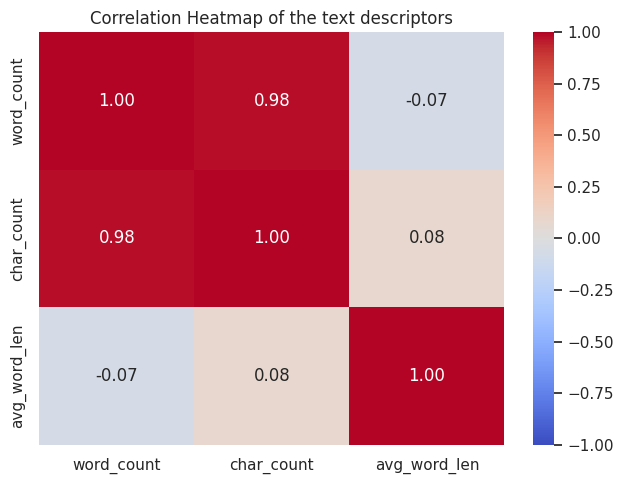

,Descriptor,F-statistic,p-value,Eta squared (effect size)
0,word_count,13.55,3.147428e-13,0.0034
1,char_count,13.28,6.006264e-13,0.0033
2,avg_word_len,11.67,2.773404e-11,0.0029


Average text length for every emotion:


,word_count,char_count,avg_word_len
emotion,,,
joy,19.44,98.17,5.07
sadness,18.41,92.76,5.06
anger,19.25,97.08,5.07
fear,18.76,95.77,5.15
love,20.68,104.14,5.04
surprise,19.77,100.51,5.10


In [15]:
# 1) Correlation between the numeric descriptors
correlation = data[num_cols].corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of the text descriptors")
save_fig("05_correlation_heatmap")

# 2) ANOVA: does the descriptor differ between the six emotions?  (eta squared = share of variance explained by the emotion)
anova_rows = []
for col in num_cols:
    groups = [g[col].values for _, g in data.groupby("emotion")]
    f_stat, p_val = stats.f_oneway(*groups)
    grand = data[col].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = float(((data[col] - grand) ** 2).sum())
    anova_rows.append({"Descriptor": col, "F-statistic": round(f_stat, 2), "p-value": p_val,
                       "Eta squared (effect size)": round(ss_between / ss_total, 4)})
anova_table = pd.DataFrame(anova_rows)
display(anova_table)

print("Average text length for every emotion:")
display(data.groupby("emotion")[num_cols].mean().round(2).loc[class_counts.index])

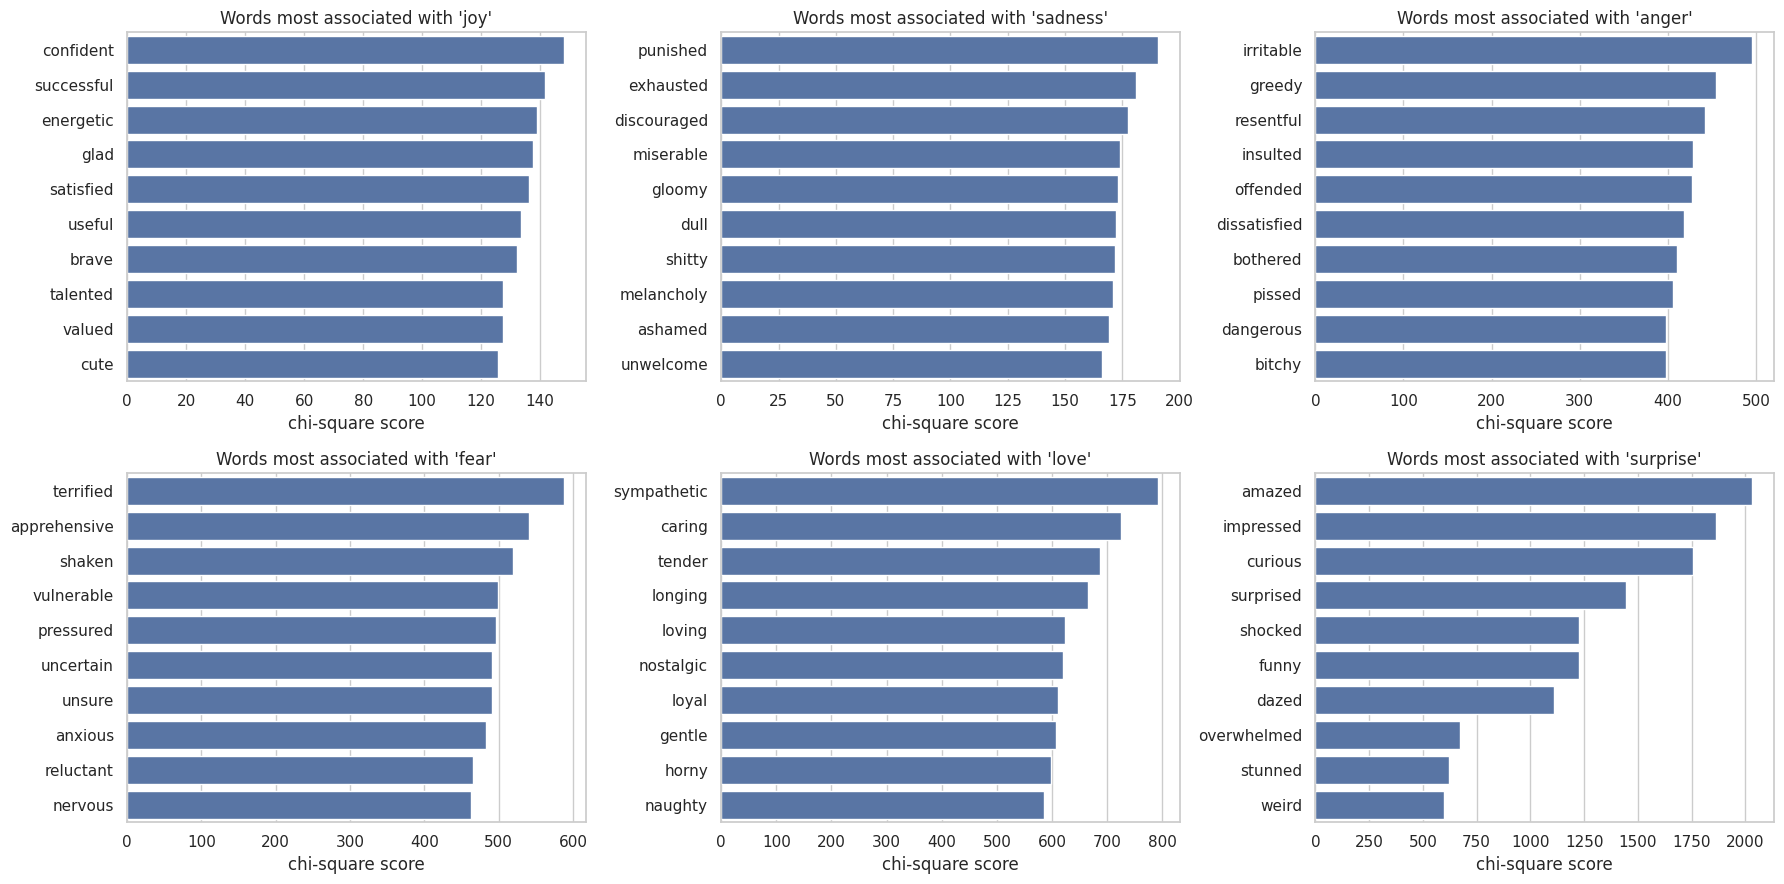

,word 1,word 2,word 3,word 4,word 5,word 6,word 7,word 8,word 9,word 10
joy,confident,successful,energetic,glad,satisfied,useful,brave,talented,valued,cute
sadness,punished,exhausted,discouraged,miserable,gloomy,dull,shitty,melancholy,ashamed,unwelcome
anger,irritable,greedy,resentful,insulted,offended,dissatisfied,bothered,pissed,dangerous,bitchy
fear,terrified,apprehensive,shaken,vulnerable,pressured,uncertain,unsure,anxious,reluctant,nervous
love,sympathetic,caring,tender,longing,loving,nostalgic,loyal,gentle,horny,naughty
surprise,amazed,impressed,curious,surprised,shocked,funny,dazed,overwhelmed,stunned,weird


In [16]:
# 3) Words that are most strongly associated with each emotion (chi-square test, one emotion against the rest)
cv_words = CountVectorizer(stop_words="english", min_df=5, binary=True)
X_words = cv_words.fit_transform(data["text"])
vocab = np.array(cv_words.get_feature_names_out())

top_words = {}
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, emo in zip(axes.ravel(), class_counts.index):
    is_emo = (data["emotion"] == emo).values
    in_class = np.asarray(X_words[is_emo].sum(axis=0)).ravel() / is_emo.sum()
    overall = np.asarray(X_words.sum(axis=0)).ravel() / len(data)
    scores, _ = chi2(X_words, is_emo.astype(int))
    scores = np.where(in_class > overall, scores, 0)       # keep only words that are MORE frequent in this emotion
    idx = np.argsort(scores)[::-1][:10]
    top_words[emo] = list(vocab[idx])
    sns.barplot(x=scores[idx], y=vocab[idx], ax=ax)
    ax.set_title(f"Words most associated with '{emo}'")
    ax.set_xlabel("chi-square score")
save_fig("06_top_words_per_emotion")

display(pd.DataFrame(top_words).T.rename(columns=lambda i: f"word {i + 1}"))

In [17]:
strongest = anova_table.sort_values("Eta squared (effect size)", ascending=False).iloc[0]
say(f"Interpretation (correlation): the word count and the character count are almost perfectly correlated "
    f"(r = {correlation.loc['word_count', 'char_count']:.2f}), so they carry the same information. "
    f"The ANOVA shows that the average length differs between emotions (largest effect: {strongest['Descriptor']}, eta squared = {strongest['Eta squared (effect size)']:.3f}); "
    f"an eta squared this small means that the length of a text explains only a tiny part of the emotion, so length alone cannot predict it. "
    f"The chi-square analysis is far more informative: every emotion has its own typical vocabulary "
    f"(for example '{top_words[class_counts.index[0]][0]}' for {class_counts.index[0]} and '{top_words[class_counts.index[-1]][0]}' for {class_counts.index[-1]}). "
    f"This is exactly what a TF-IDF based classifier can exploit.")

Interpretation (correlation): the word count and the character count are almost perfectly correlated (r =
0.98), so they carry the same information. The ANOVA shows that the average length differs between emotions
(largest effect: word_count, eta squared = 0.003); an eta squared this small means that the length of a text
explains only a tiny part of the emotion, so length alone cannot predict it. The chi-square analysis is far
more informative: every emotion has its own typical vocabulary (for example 'confident' for joy and 'amazed'
for surprise). This is exactly what a TF-IDF based classifier can exploit.


## 1.7 Feature encoding
Both columns are non-numeric, so two encodings are needed:

| Original | Encoding / transformation | Reason |
|---|---|---|
| `emotion` (target) | **Label encoding** (`LabelEncoder`: 0 … 5) | classifiers need integer class labels; the mapping is kept so that predictions can be translated back to emotion names |
| `text` (input) | **TF-IDF vectorisation** (unigrams + bigrams, 5 000 most useful terms, sublinear term frequency) | turns every sentence into a numeric vector; frequent but uninformative words get a low weight, distinctive words a high weight |

The TF-IDF vectoriser is placed **inside a `Pipeline`**, so it is fitted on the training data only (no data leakage). Because the vocabulary and the IDF weights come from the training part, words that only appear in the test set are simply ignored, as they would be for new data in real life. Tree-based models do not need scaling and TF-IDF vectors are already length-normalised, so no extra scaler is used.

In [18]:
# Encode the target
le = LabelEncoder()
y_encoded = le.fit_transform(data["emotion"])
CLASS_NAMES = list(le.classes_)
n_classes = len(CLASS_NAMES)

print("TARGET ENCODING (LabelEncoder)")
display(pd.DataFrame({"Emotion": CLASS_NAMES, "Encoded value": range(n_classes)}))

# Independent variable (text) and target
X = data["text"].copy()
y = pd.Series(y_encoded, index=data.index, name="emotion_encoded")

print("Input shape :", X.shape)
print("Target shape:", y.shape)
print("Missing values in text  :", int(X.isnull().sum()))
print("Missing values in target:", int(y.isnull().sum()))

# TF-IDF settings used by EVERY model of this project (the vectoriser is always re-fitted inside a pipeline)
def make_tfidf():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True)

TARGET ENCODING (LabelEncoder)


,Emotion,Encoded value
0,anger,0
1,fear,1
2,joy,2
3,love,3
4,sadness,4
5,surprise,5


Input shape : (19897,)
Target shape: (19897,)
Missing values in text  : 0
Missing values in target: 0


## 1.8 Train-test split (70 : 30)
The sentences are **independent observations** (they are not a time series), so a **random** 70 : 30 split is appropriate. The split is **stratified** by emotion, so that the rare classes (e.g. the smallest one) appear in the training and the test set in the same proportion as in the full data. `random_state` is fixed so that the split is reproducible.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)

print("Training samples:", X_train.shape)
print("Testing samples :", X_test.shape)
print("Training percentage:", round(len(X_train) / len(data) * 100, 2))
print("Testing percentage :", round(len(X_test) / len(data) * 100, 2))

# The train and test sets should have the same class distribution (thanks to stratification)
split_check = pd.DataFrame({
    "Train %": (pd.Series(y_train).map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True) * 100).round(2),
    "Test %":  (pd.Series(y_test).map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True) * 100).round(2),
}).loc[class_counts.index]
display(split_check)

# Illustration only: what the TF-IDF representation of the training data looks like
demo_vec = make_tfidf().fit(X_train)
demo_matrix = demo_vec.transform(X_train)
density = demo_matrix.nnz / (demo_matrix.shape[0] * demo_matrix.shape[1]) * 100
print("\nTF-IDF matrix of the training data:", demo_matrix.shape, f"(only {density:.2f}% of the cells are non-zero)")
print("Examples of learned terms:", list(demo_vec.get_feature_names_out()[:5]), "...", list(demo_vec.get_feature_names_out()[-5:]))

Training samples: (13927,)
Testing samples : (5970,)
Training percentage: 70.0
Testing percentage : 30.0


,Train %,Test %
emotion,,
joy,33.81,33.82
sadness,29.10,29.10
anger,13.57,13.57
fear,11.85,11.84
love,8.10,8.11
surprise,3.56,3.57



TF-IDF matrix of the training data: (13927, 5000) (only 0.40% of the cells are non-zero)
Examples of learned terms: ['abandoned', 'abilities', 'ability', 'ability to', 'able'] ... ['your life', 'youre', 'yours', 'yourself', 'youve']


---
# WEEK 1 — Baseline Modeling (Classification)

Required classification baselines: **Logistic Regression, Decision Tree, KNN**.
Metrics: **Accuracy, Precision, Recall, F1 Score and Confusion Matrix**. *All baselines are evaluated on exactly the same test set.*
Precision, Recall and F1 are **macro-averaged** (every emotion has the same weight, however rare it is); the weighted F1 is shown as well.

> Regression models and metrics (Linear Regression, MAE, RMSE, R²) are **not applicable** because `emotion` is a categorical target.

In [20]:
# Containers that store the results of every model (re-running a cell simply overwrites the entry)
results = {}        # model name -> test metrics
predictions = {}    # model name -> test-set predictions
probabilities = {}  # model name -> test-set class probabilities
models = {}         # model name -> fitted model

def evaluate_model(name, y_true, y_pred, y_proba=None, verbose=True):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    row = {
        "Model": name,
        "Accuracy":          accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)":        f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (weighted)":     f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (OvR)":     roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro") if y_proba is not None else np.nan,
    }
    results[name] = row
    predictions[name] = y_pred
    if y_proba is not None:
        probabilities[name] = np.asarray(y_proba)
    if verbose:
        print(name)
        for k in ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 (weighted)", "ROC-AUC (OvR)"]:
            print(f"  {k:<18}:", round(row[k], 4))
        print("-" * 40)

def evaluate_fitted(name, model, verbose=True):
    # Predict the test set with a fitted pipeline and store every metric
    evaluate_model(name, y_test, model.predict(X_test), model.predict_proba(X_test), verbose)

def results_table(names=None):
    table = pd.DataFrame(list(results.values()))
    if names is not None:
        table = table[table["Model"].isin(names)]
    return table.sort_values("F1 (macro)", ascending=False).reset_index(drop=True)

# 1) Logistic Regression
lr_model = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])
lr_model.fit(X_train, y_train)
models["Logistic Regression"] = lr_model
evaluate_fitted("Logistic Regression", lr_model)

Logistic Regression
  Accuracy          : 0.8367
  Precision (macro) : 0.8597
  Recall (macro)    : 0.7117
  F1 (macro)        : 0.7613
  F1 (weighted)     : 0.8283
  ROC-AUC (OvR)     : 0.982
----------------------------------------


In [21]:
# 2) Decision Tree
dt_model = Pipeline([("tfidf", make_tfidf()),
                     ("clf", DecisionTreeClassifier(max_depth=20, min_samples_split=10, random_state=SEED))])
dt_model.fit(X_train, y_train)
models["Decision Tree"] = dt_model
evaluate_fitted("Decision Tree", dt_model)

Decision Tree
  Accuracy          : 0.4013
  Precision (macro) : 0.7459
  Recall (macro)    : 0.2995
  F1 (macro)        : 0.2897
  F1 (weighted)     : 0.2842
  ROC-AUC (OvR)     : 0.5994
----------------------------------------


In [22]:
# 3) KNN (cosine distance is the natural distance between TF-IDF vectors)
knn_model = Pipeline([("tfidf", make_tfidf()),
                      ("clf", KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute"))])
knn_model.fit(X_train, y_train)
models["KNN"] = knn_model
evaluate_fitted("KNN", knn_model)

KNN
  Accuracy          : 0.5675
  Precision (macro) : 0.5455
  Recall (macro)    : 0.4655
  F1 (macro)        : 0.4878
  F1 (weighted)     : 0.5591
  ROC-AUC (OvR)     : 0.7806
----------------------------------------


BASELINE MODEL COMPARISON TABLE (same test set: 5970 samples)


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OvR)
0,Logistic Regression,0.8367,0.8597,0.7117,0.7613,0.8283,0.9820
1,KNN,0.5675,0.5455,0.4655,0.4878,0.5591,0.7806
2,Decision Tree,0.4013,0.7459,0.2995,0.2897,0.2842,0.5994


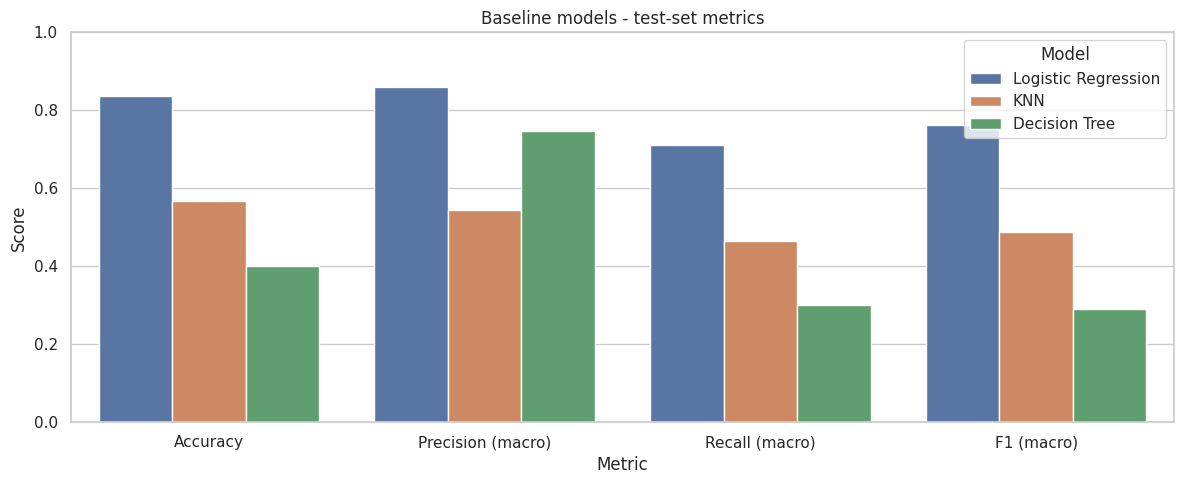

In [23]:
BASELINE_MODELS = ["Logistic Regression", "Decision Tree", "KNN"]

baseline_results = results_table(BASELINE_MODELS)
print("BASELINE MODEL COMPARISON TABLE (same test set: {} samples)".format(len(y_test)))
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 (weighted)", "ROC-AUC (OvR)"]
display(baseline_results.style.format({c: "{:.4f}" for c in metric_cols}))

# Visual comparison of the three baselines
plot_df = baseline_results.melt(id_vars="Model", value_vars=["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"],
                                var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1)
plt.title("Baseline models - test-set metrics")
save_fig("07_baseline_comparison")

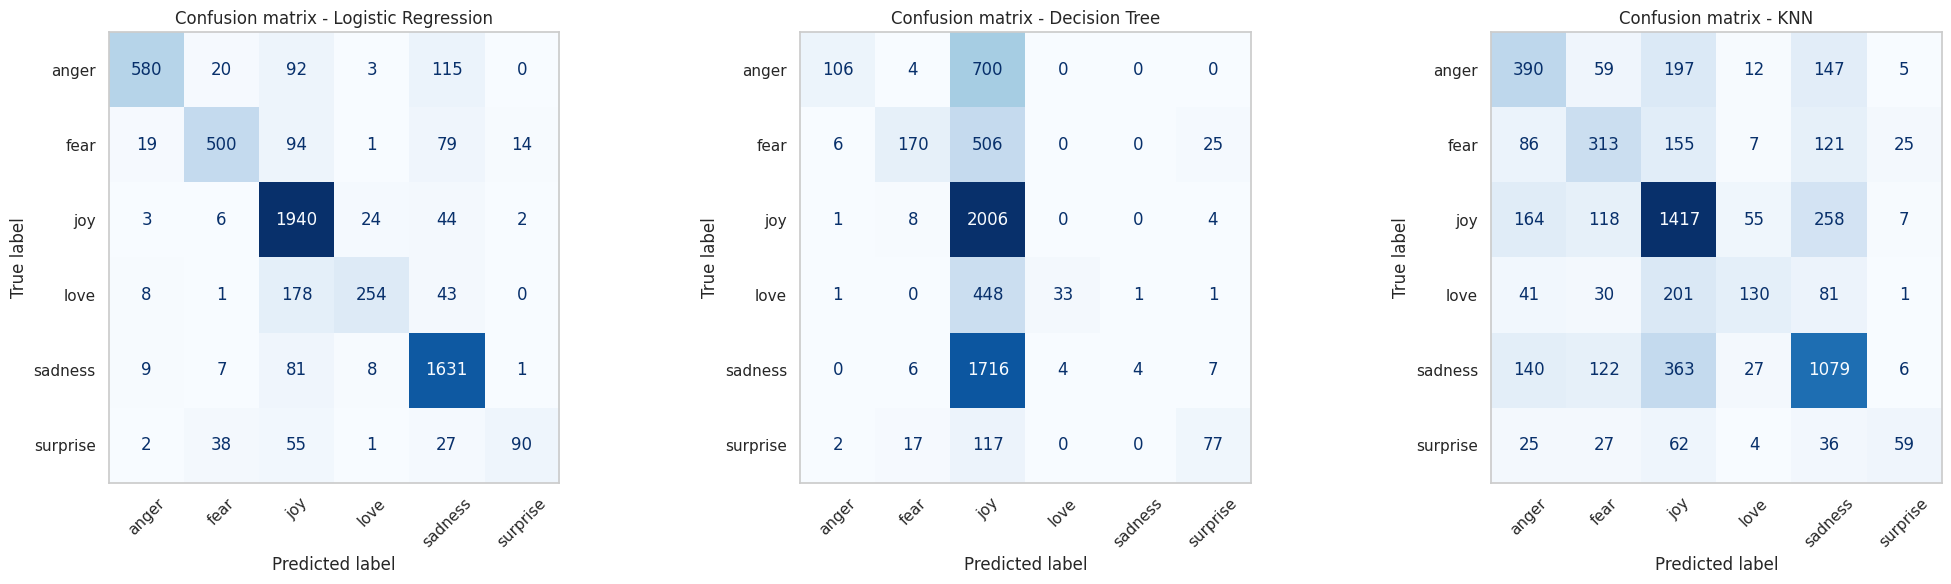

In [24]:
# Confusion matrices of the three baselines (rows = true emotion, columns = predicted emotion)
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, name in zip(axes, BASELINE_MODELS):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], display_labels=CLASS_NAMES, ax=ax,
                                            colorbar=False, cmap="Blues", xticks_rotation=45)
    ax.set_title(f"Confusion matrix - {name}")
    ax.grid(False)
save_fig("08_baseline_confusion_matrices")

In [25]:
# Auto-generated interpretation paragraph (always matches the numbers above)
best_b, worst_b = baseline_results.iloc[0], baseline_results.iloc[-1]
gap = best_b["Accuracy"] - best_b["F1 (macro)"]

# Which emotion is recognised worst by the best baseline?
rec_per_class = recall_score(y_test, predictions[best_b["Model"]], average=None, zero_division=0)
worst_class, best_class = CLASS_NAMES[int(np.argmin(rec_per_class))], CLASS_NAMES[int(np.argmax(rec_per_class))]

baseline_interpretation = (
    f"Among the baseline models, {best_b['Model']} performed best with Accuracy = {best_b['Accuracy']:.4f}, Precision = {best_b['Precision (macro)']:.4f}, "
    f"Recall = {best_b['Recall (macro)']:.4f} and macro-F1 = {best_b['F1 (macro)']:.4f}, while {worst_b['Model']} was the weakest "
    f"(Accuracy = {worst_b['Accuracy']:.4f}, macro-F1 = {worst_b['F1 (macro)']:.4f}). "
    f"For the best baseline the accuracy is {gap:.3f} higher than the macro-F1: this gap is caused by the class imbalance, because the frequent emotions "
    f"are recognised better than the rare ones - '{worst_class}' has the lowest recall ({rec_per_class.min():.2f}) and '{best_class}' the highest ({rec_per_class.max():.2f}). "
    f"Linear models typically work well on TF-IDF features because the emotions are largely recognisable from individual words; a single Decision Tree has to split on one word at a time "
    f"in a very sparse space and typically over-fits, and KNN is affected by the high dimensionality of text vectors. "
    f"The confusion matrices show which emotions are mixed up. These baselines set the reference performance that the advanced models of Week 2 must beat.")
say("Interpretation: " + baseline_interpretation)

Interpretation: Among the baseline models, Logistic Regression performed best with Accuracy = 0.8367,
Precision = 0.8597, Recall = 0.7117 and macro-F1 = 0.7613, while Decision Tree was the weakest (Accuracy =
0.4013, macro-F1 = 0.2897). For the best baseline the accuracy is 0.075 higher than the macro-F1: this gap is
caused by the class imbalance, because the frequent emotions are recognised better than the rare ones -
'surprise' has the lowest recall (0.42) and 'joy' the highest (0.96). Linear models typically work well on TF-
IDF features because the emotions are largely recognisable from individual words; a single Decision Tree has
to split on one word at a time in a very sparse space and typically over-fits, and KNN is affected by the high
dimensionality of text vectors. The confusion matrices show which emotions are mixed up. These baselines set
the reference performance that the advanced models of Week 2 must beat.


---
# WEEK 2 — Advanced Modeling & Optimization

* **Random Forest** and **Gradient Boosting (XGBoost)**
* **Hyper-parameter tuning:** `GridSearchCV` for every advanced model (and for the baselines, for a fair comparison)
* **Cross-validation:** 5-fold *stratified* cross-validation on the training data (the test set is never used for tuning or selection)
* **Classification-specific analysis:** ROC curves, AUC score and handling of the class imbalance

(Residual analysis is a regression technique and is therefore not applicable here.)

### Handling the class imbalance
The smallest class has far fewer examples than the largest one. Two standard remedies are **SMOTE** (create synthetic minority samples) and **class weights** (let mistakes on a rare class cost more). **Class weights** are used in this project: SMOTE would have to invent synthetic points in a 5 000-dimensional sparse TF-IDF space, and these points do not correspond to real sentences, whereas class weights keep the data real, need no extra memory and are applied consistently inside cross-validation. Logistic Regression, Decision Tree and Random Forest use `class_weight="balanced"`; XGBoost uses balanced sample weights.

In [26]:
# Shared settings for every grid search ---------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"f1_macro": "f1_macro", "accuracy": "accuracy",
           "precision_macro": "precision_macro", "recall_macro": "recall_macro"}

cv_rows = []          # cross-validation scores of every model
tuning_summary = []   # best parameters of every search

# Balanced sample weights (used by XGBoost, which has no class_weight parameter)
sw_train = compute_sample_weight(class_weight="balanced", y=y_train)
weights_table = pd.DataFrame({"Emotion": CLASS_NAMES,
                              "Training samples": np.bincount(y_train, minlength=n_classes),
                              "Balanced class weight": [round(float(sw_train[np.asarray(y_train) == i][0]), 3) for i in range(n_classes)]})
print("CLASS WEIGHTS used to handle the imbalance")
display(weights_table)

def tune(name, pipeline, grid, fit_params=None):
    # GridSearchCV with 5-fold stratified CV; the best model is refitted on the whole training set (selection by macro-F1)
    gs = GridSearchCV(pipeline, grid, cv=cv, scoring=SCORING, refit="f1_macro", n_jobs=-1, verbose=1)
    gs.fit(X_train, y_train, **(fit_params or {}))
    i, r = gs.best_index_, gs.cv_results_
    cv_rows.append({"Model": name,
                    "CV Accuracy": r["mean_test_accuracy"][i], "CV Precision (macro)": r["mean_test_precision_macro"][i],
                    "CV Recall (macro)": r["mean_test_recall_macro"][i],
                    "CV F1 (macro)": r["mean_test_f1_macro"][i], "CV F1 (std)": r["std_test_f1_macro"][i]})
    tuning_summary.append({"Model": name, "Method": "GridSearchCV", "Best parameters": str(gs.best_params_),
                           "CV F1 (macro)": gs.best_score_})
    models[name] = gs.best_estimator_
    print("Best", name, "parameters:", gs.best_params_)
    print("Best CV macro-F1:", round(gs.best_score_, 4))
    evaluate_fitted(name, gs.best_estimator_)
    return gs

# ---- Random Forest: GridSearchCV ----
rf_grid = tune(
    "Tuned Random Forest",
    Pipeline([("tfidf", make_tfidf()),
              ("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=1))]),
    {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 40], "clf__min_samples_leaf": [1, 2]},
)

CLASS WEIGHTS used to handle the imbalance


,Emotion,Training samples,Balanced class weight
0,anger,1890,1.228
1,fear,1651,1.406
2,joy,4709,0.493
3,love,1128,2.058
4,sadness,4053,0.573
5,surprise,496,4.680


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Tuned Random Forest parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
Best CV macro-F1: 0.842
Tuned Random Forest
  Accuracy          : 0.871
  Precision (macro) : 0.8346
  Recall (macro)    : 0.8498
  F1 (macro)        : 0.8406
  F1 (weighted)     : 0.8719
  ROC-AUC (OvR)     : 0.9821
----------------------------------------


In [27]:
# ---- Gradient Boosting (XGBoost): GridSearchCV (balanced sample weights handle the imbalance) ----
xgb_grid = tune(
    "Tuned XGBoost",
    Pipeline([("tfidf", make_tfidf()),
              ("clf", XGBClassifier(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss",
                                    random_state=SEED, n_jobs=1))]),
    {"clf__n_estimators": [100, 200], "clf__max_depth": [4, 6], "clf__learning_rate": [0.1, 0.3]},
    fit_params={"clf__sample_weight": sw_train},
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Tuned XGBoost parameters: {'clf__learning_rate': 0.3, 'clf__max_depth': 6, 'clf__n_estimators': 200}
Best CV macro-F1: 0.8577
Tuned XGBoost
  Accuracy          : 0.8886
  Precision (macro) : 0.8467
  Recall (macro)    : 0.8696
  F1 (macro)        : 0.8568
  F1 (weighted)     : 0.8896
  ROC-AUC (OvR)     : 0.9849
----------------------------------------


In [28]:
# ---- Tune the baselines too (fair comparison): Logistic Regression, Decision Tree and KNN with GridSearchCV ----
lr_grid = tune(
    "Tuned Logistic Regression",
    Pipeline([("tfidf", make_tfidf()),
              ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]),
    {"clf__C": [0.3, 1, 3, 10], "tfidf__ngram_range": [(1, 1), (1, 2)]},
)

dt_grid = tune(
    "Tuned Decision Tree",
    Pipeline([("tfidf", make_tfidf()),
              ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
    {"clf__max_depth": [10, 20, 40, None], "clf__min_samples_leaf": [1, 2, 5]},
)

knn_grid = tune(
    "Tuned KNN",
    Pipeline([("tfidf", make_tfidf()),
              ("clf", KNeighborsClassifier(metric="cosine", algorithm="brute"))]),
    {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]},
)

print("HYPER-PARAMETER TUNING SUMMARY")
tuning_table = pd.DataFrame(tuning_summary).sort_values("CV F1 (macro)", ascending=False).reset_index(drop=True)
display(tuning_table)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Tuned Logistic Regression parameters: {'clf__C': 10, 'tfidf__ngram_range': (1, 1)}
Best CV macro-F1: 0.8557
Tuned Logistic Regression
  Accuracy          : 0.8893
  Precision (macro) : 0.8441
  Recall (macro)    : 0.871
  F1 (macro)        : 0.8556
  F1 (weighted)     : 0.8902
  ROC-AUC (OvR)     : 0.9861
----------------------------------------
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Tuned Decision Tree parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
Best CV macro-F1: 0.8185
Tuned Decision Tree
  Accuracy          : 0.8581
  Precision (macro) : 0.8009
  Recall (macro)    : 0.8642
  F1 (macro)        : 0.8253
  F1 (weighted)     : 0.8609
  ROC-AUC (OvR)     : 0.9456
----------------------------------------
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Tuned KNN parameters: {'clf__n_neighbors': 21, 'clf__weights': 'distance'}
Best CV macro-F1: 0.5295
Tuned KNN
 

,Model,Method,Best parameters,CV F1 (macro)
0,Tuned XGBoost,GridSearchCV,"{'clf__learning_rate': 0.3, 'clf__max_depth': ...",0.857714
1,Tuned Logistic Regression,GridSearchCV,"{'clf__C': 10, 'tfidf__ngram_range': (1, 1)}",0.855671
2,Tuned Random Forest,GridSearchCV,"{'clf__max_depth': None, 'clf__min_samples_lea...",0.842031
3,Tuned Decision Tree,GridSearchCV,"{'clf__max_depth': None, 'clf__min_samples_lea...",0.818469
4,Tuned KNN,GridSearchCV,"{'clf__n_neighbors': 21, 'clf__weights': 'dist...",0.529545


In [29]:
best_cv_row = tuning_table.iloc[0]
say(f"Interpretation (tuning): GridSearchCV evaluates every combination of the parameter grid with 5-fold stratified cross-validation and keeps the one with the "
    f"highest macro-F1. The best tuned model is {best_cv_row['Model']} (CV macro-F1 = {best_cv_row['CV F1 (macro)']:.3f}). The tuning is done on the training data only, "
    f"so the test set stays untouched for the final, unbiased evaluation. The TF-IDF vectoriser is re-fitted inside every fold, so the validation fold never leaks into the vocabulary. "
    f"Limiting the depth of the trees, the learning rate or the strength of the regularisation (C) controls over-fitting on high-dimensional text data. "
    f"Macro-F1 was chosen as the tuning metric because it rewards a model only if it also recognises the rare emotions.")

Interpretation (tuning): GridSearchCV evaluates every combination of the parameter grid with 5-fold stratified
cross-validation and keeps the one with the highest macro-F1. The best tuned model is Tuned XGBoost (CV
macro-F1 = 0.858). The tuning is done on the training data only, so the test set stays untouched for the
final, unbiased evaluation. The TF-IDF vectoriser is re-fitted inside every fold, so the validation fold never
leaks into the vocabulary. Limiting the depth of the trees, the learning rate or the strength of the
regularisation (C) controls over-fitting on high-dimensional text data. Macro-F1 was chosen as the tuning
metric because it rewards a model only if it also recognises the rare emotions.


### Effect of the class weights (class-imbalance handling)
The same model is trained **with and without** class weights, so that the effect on the rarest emotion can be seen directly.

In [30]:
minority_name = class_counts.idxmin()
minority_idx = CLASS_NAMES.index(minority_name)

def imbalance_row(label, model):
    pred = model.predict(X_test)
    return {"Model": label, "Accuracy": accuracy_score(y_test, pred),
            "F1 (macro)": f1_score(y_test, pred, average="macro"),
            f"Recall of '{minority_name}' (rarest class)": recall_score(y_test, pred, labels=[minority_idx], average=None, zero_division=0)[0]}

lr_bal = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]).fit(X_train, y_train)
dt_bal = Pipeline([("tfidf", make_tfidf()),
                   ("clf", DecisionTreeClassifier(max_depth=20, min_samples_split=10, class_weight="balanced", random_state=SEED))]).fit(X_train, y_train)

imb_table = pd.DataFrame([
    imbalance_row("Logistic Regression - no class weights", models["Logistic Regression"]),
    imbalance_row("Logistic Regression - class_weight='balanced'", lr_bal),
    imbalance_row("Decision Tree - no class weights", models["Decision Tree"]),
    imbalance_row("Decision Tree - class_weight='balanced'", dt_bal),
])
display(imb_table.style.format({c: "{:.4f}" for c in imb_table.columns[1:]}))

rec_col = imb_table.columns[-1]
d_rec = imb_table.loc[1, rec_col] - imb_table.loc[0, rec_col]
d_f1 = imb_table.loc[1, "F1 (macro)"] - imb_table.loc[0, "F1 (macro)"]
d_acc = imb_table.loc[1, "Accuracy"] - imb_table.loc[0, "Accuracy"]
say(f"Interpretation (class imbalance): with class weights the recall of the rarest emotion '{minority_name}' changes by {d_rec:+.3f} for Logistic Regression, "
    f"the macro-F1 by {d_f1:+.3f} and the accuracy by {d_acc:+.3f}. Class weights make a mistake on a rare emotion more expensive, so the model stops "
    f"ignoring it; the price is usually a few more false alarms for that class (lower precision) and a small change in overall accuracy. "
    f"KNN has no class-weight option, which is one more reason to expect it to favour the frequent emotions.")

,Model,Accuracy,F1 (macro),Recall of 'surprise' (rarest class)
0,Logistic Regression - no class weights,0.8367,0.7613,0.4225
1,Logistic Regression - class_weight='balanced',0.8704,0.8397,0.9014
2,Decision Tree - no class weights,0.4013,0.2897,0.3615
3,Decision Tree - class_weight='balanced',0.1940,0.2511,0.8263


Interpretation (class imbalance): with class weights the recall of the rarest emotion 'surprise' changes by
+0.479 for Logistic Regression, the macro-F1 by +0.078 and the accuracy by +0.034. Class weights make a
mistake on a rare emotion more expensive, so the model stops ignoring it; the price is usually a few more
false alarms for that class (lower precision) and a small change in overall accuracy. KNN has no class-weight
option, which is one more reason to expect it to favour the frequent emotions.


### Cross-validation of all models
Every model (baselines and tuned models) is scored with the **same 5 stratified folds** on the training data, so the comparison is fair. The scores of the tuned models come from the grid search itself (they were selected on these folds, so they are slightly optimistic — the untouched test set gives the final, unbiased result).

5-FOLD STRATIFIED CROSS-VALIDATION RESULTS (training data)


,Model,CV Accuracy,CV Precision (macro),CV Recall (macro),CV F1 (macro),CV F1 (std)
0,Tuned XGBoost,0.8854,0.8464,0.8717,0.8577,0.0054
1,Tuned Logistic Regression,0.8873,0.8478,0.8650,0.8557,0.0020
2,Tuned Random Forest,0.8650,0.8387,0.8481,0.8420,0.0091
3,Tuned Decision Tree,0.8447,0.7957,0.8514,0.8185,0.0051
4,Logistic Regression,0.8235,0.8620,0.6857,0.7368,0.0139
5,Tuned KNN,0.6338,0.7278,0.4817,0.5295,0.0087
6,KNN,0.5733,0.5642,0.4664,0.4881,0.0070
7,Decision Tree,0.4027,0.6618,0.3059,0.3051,0.0109


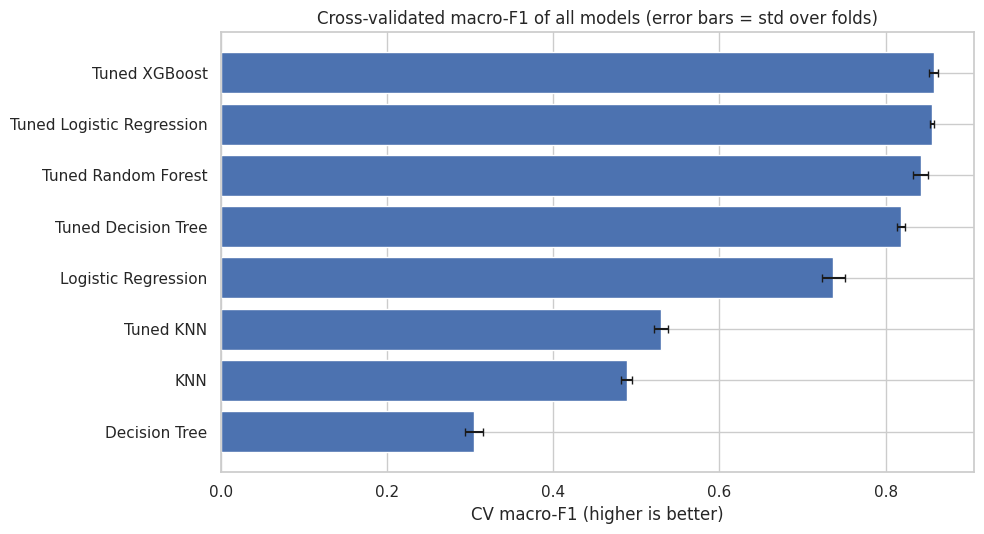

Interpretation (cross-validation): Tuned XGBoost has the highest average validation macro-F1 (0.858) and an
average accuracy of 0.885. The standard deviation shows how stable each model is across the folds - a small
value means the performance does not depend on a particular subset of the data.


In [31]:
def baseline_cv(name, estimator):
    s = cross_validate(estimator, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_rows.append({"Model": name,
                    "CV Accuracy": s["test_accuracy"].mean(), "CV Precision (macro)": s["test_precision_macro"].mean(),
                    "CV Recall (macro)": s["test_recall_macro"].mean(),
                    "CV F1 (macro)": s["test_f1_macro"].mean(), "CV F1 (std)": s["test_f1_macro"].std()})

for baseline_name in BASELINE_MODELS:
    baseline_cv(baseline_name, models[baseline_name])

cv_table = pd.DataFrame(cv_rows).sort_values("CV F1 (macro)", ascending=False).reset_index(drop=True)
print("5-FOLD STRATIFIED CROSS-VALIDATION RESULTS (training data)")
display(cv_table.style.format({c: "{:.4f}" for c in cv_table.columns[1:]}))

plt.figure(figsize=(10, 5.5))
plt.barh(cv_table["Model"][::-1], cv_table["CV F1 (macro)"][::-1], xerr=cv_table["CV F1 (std)"][::-1], capsize=3)
plt.xlabel("CV macro-F1 (higher is better)")
plt.title("Cross-validated macro-F1 of all models (error bars = std over folds)")
save_fig("09_cv_f1")

say(f"Interpretation (cross-validation): {cv_table.iloc[0]['Model']} has the highest average validation macro-F1 "
    f"({cv_table.iloc[0]['CV F1 (macro)']:.3f}) and an average accuracy of {cv_table.iloc[0]['CV Accuracy']:.3f}. "
    f"The standard deviation shows how stable each model is across the folds - a small value means the performance does not depend on a particular "
    f"subset of the data.")

FINAL MODEL COMPARISON (sorted by test macro-F1; CV F1 = validation on the training data)


,Rank,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OvR),CV F1 (macro)
0,1,Tuned XGBoost,0.8886,0.8467,0.8696,0.8568,0.8896,0.9849,0.8577
1,2,Tuned Logistic Regression,0.8893,0.8441,0.8710,0.8556,0.8902,0.9861,0.8557
2,3,Tuned Random Forest,0.8710,0.8346,0.8498,0.8406,0.8719,0.9821,0.8420
3,4,Tuned Decision Tree,0.8581,0.8009,0.8642,0.8253,0.8609,0.9456,0.8185
4,5,Logistic Regression,0.8367,0.8597,0.7117,0.7613,0.8283,0.9820,0.7368
5,6,Tuned KNN,0.6335,0.7047,0.4781,0.5228,0.6094,0.8627,0.5295
6,7,KNN,0.5675,0.5455,0.4655,0.4878,0.5591,0.7806,0.4881
7,8,Decision Tree,0.4013,0.7459,0.2995,0.2897,0.2842,0.5994,0.3051


SELECTED MODEL (highest cross-validated macro-F1): Tuned XGBoost


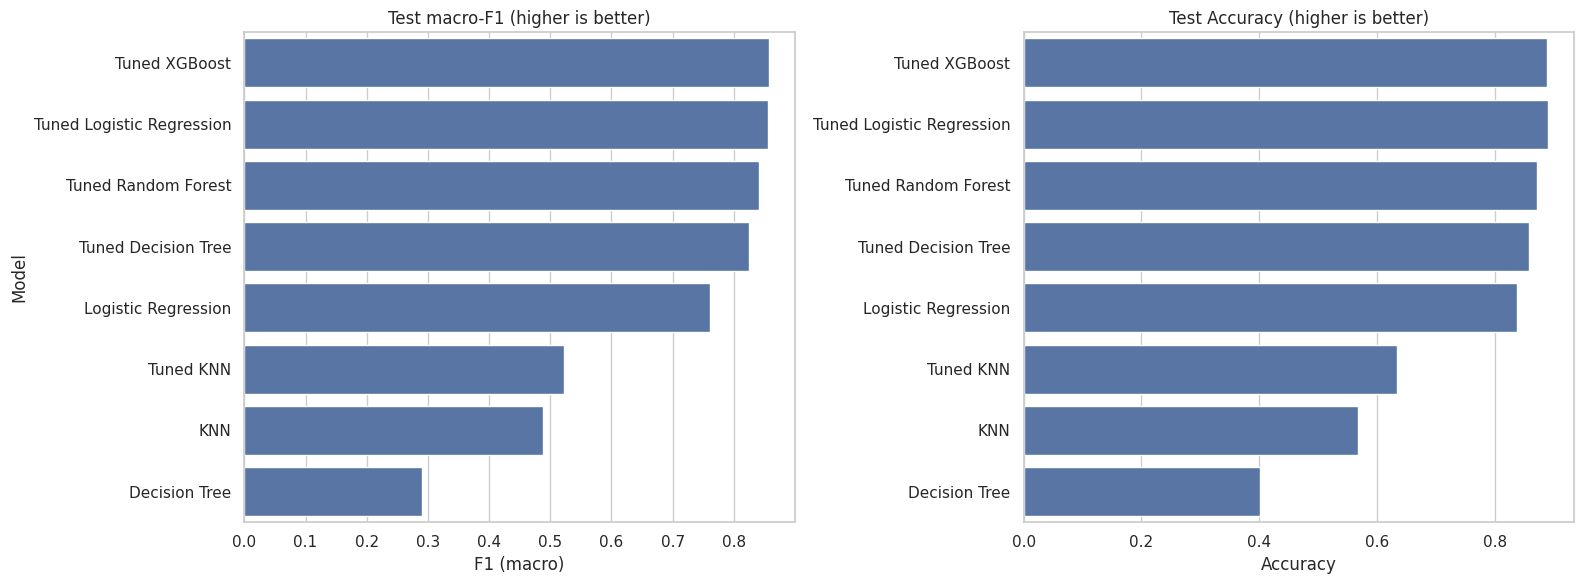

In [32]:
# ---------------------------------------------------------------
# FINAL MODEL COMPARISON (all models, same test set)
# ---------------------------------------------------------------
final_comparison = results_table()
cv_f1 = cv_table.set_index("Model")["CV F1 (macro)"]
final_comparison["CV F1 (macro)"] = final_comparison["Model"].map(cv_f1)
final_comparison.insert(0, "Rank", range(1, len(final_comparison) + 1))
print("FINAL MODEL COMPARISON (sorted by test macro-F1; CV F1 = validation on the training data)")
display(final_comparison.style.format({c: "{:.4f}" for c in final_comparison.columns[2:]}))

# MODEL SELECTION uses ONLY the cross-validated macro-F1. The test set is used once, for the final evaluation.
cv_pool = final_comparison.dropna(subset=["CV F1 (macro)"]).sort_values("CV F1 (macro)", ascending=False).reset_index(drop=True)
best_model_name = cv_pool.iloc[0]["Model"]
best_predictions = predictions[best_model_name]
best_proba = probabilities[best_model_name]
print("SELECTED MODEL (highest cross-validated macro-F1):", best_model_name)
if final_comparison.iloc[0]["Model"] != best_model_name:
    print("Note: the model with the highest TEST macro-F1 is", final_comparison.iloc[0]["Model"],
          "- it is NOT used for selection, to keep the test set unbiased.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
order = final_comparison["Model"]
sns.barplot(data=final_comparison, y="Model", x="F1 (macro)", order=order, ax=axes[0])
axes[0].set_title("Test macro-F1 (higher is better)")
sns.barplot(data=final_comparison, y="Model", x="Accuracy", order=order, ax=axes[1])
axes[1].set_title("Test Accuracy (higher is better)")
axes[1].set_ylabel("")
save_fig("10_model_comparison")

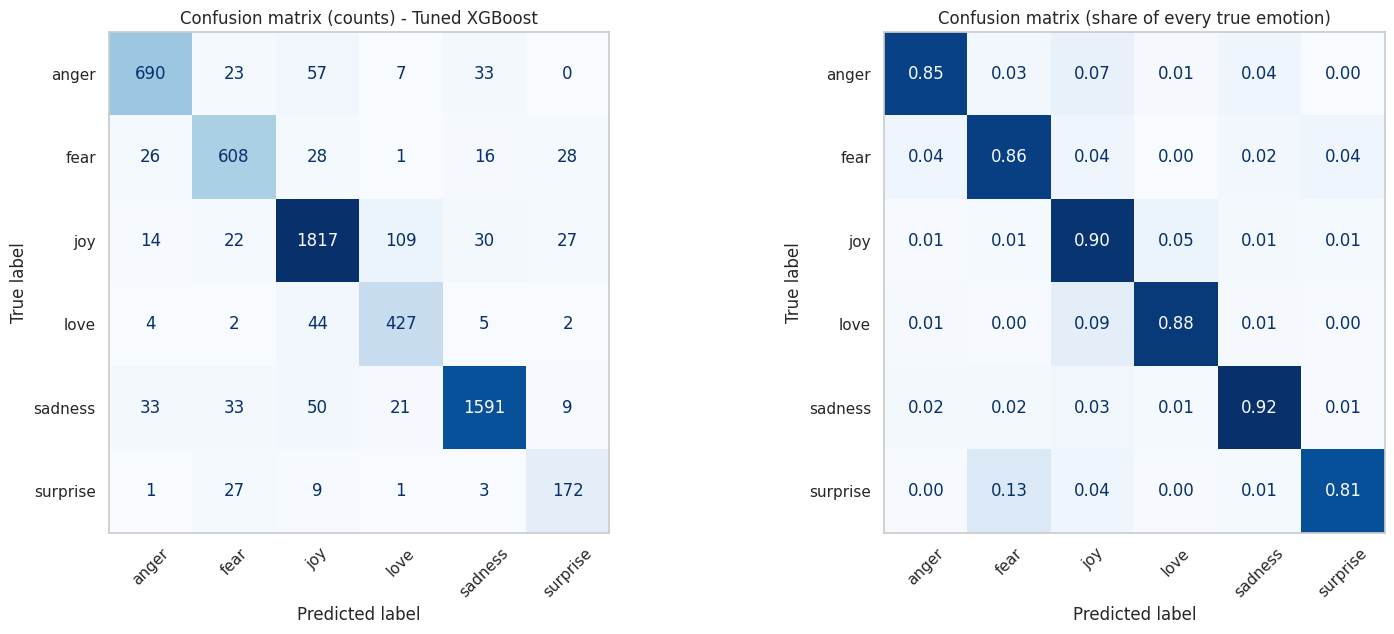

CLASSIFICATION REPORT - Tuned XGBoost


,precision,recall,f1-score,support
anger,0.8984,0.8519,0.8745,810.0000
fear,0.8503,0.8600,0.8551,707.0000
joy,0.9062,0.9000,0.9031,2019.0000
love,0.7544,0.8822,0.8133,484.0000
sadness,0.9482,0.9159,0.9318,1737.0000
surprise,0.7227,0.8075,0.7627,213.0000
accuracy,0.8886,0.8886,0.8886,0.8886
macro avg,0.8467,0.8696,0.8568,5970.0000
weighted avg,0.8919,0.8886,0.8896,5970.0000


MOST FREQUENT CONFUSIONS


,True emotion,Predicted as,Texts,Share of the true class (%)
0,joy,love,109,5.4
1,anger,joy,57,7.0
2,sadness,joy,50,2.9
3,love,joy,44,9.1
4,anger,sadness,33,4.1
5,sadness,anger,33,1.9


In [33]:
# Confusion matrix and per-class report of the selected model
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, display_labels=CLASS_NAMES, ax=axes[0],
                                        colorbar=False, cmap="Blues", xticks_rotation=45)
axes[0].set_title(f"Confusion matrix (counts) - {best_model_name}")
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, display_labels=CLASS_NAMES, ax=axes[1],
                                        colorbar=False, cmap="Blues", normalize="true", values_format=".2f", xticks_rotation=45)
axes[1].set_title("Confusion matrix (share of every true emotion)")
for ax in axes:
    ax.grid(False)
save_fig("11_confusion_matrix_best")

report = pd.DataFrame(classification_report(y_test, best_predictions, target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T
print("CLASSIFICATION REPORT -", best_model_name)
display(report.round(4))

# The most frequent confusions (off-diagonal cells of the confusion matrix)
cm = confusion_matrix(y_test, best_predictions)
pairs = [{"True emotion": CLASS_NAMES[i], "Predicted as": CLASS_NAMES[j], "Texts": int(cm[i, j]),
          "Share of the true class (%)": round(100 * cm[i, j] / cm[i].sum(), 1)}
         for i in range(n_classes) for j in range(n_classes) if i != j]
confusions = pd.DataFrame(pairs).sort_values("Texts", ascending=False).head(6).reset_index(drop=True)
print("MOST FREQUENT CONFUSIONS")
display(confusions)

### ROC curve and AUC score
For a multi-class problem the ROC curve is drawn **one-vs-rest**: each emotion is treated as the "positive" class against all other emotions. The **AUC** is the area under such a curve (1.0 = perfect ranking, 0.5 = random guessing); the **macro-average** AUC gives every emotion the same weight. The curves use the predicted *probabilities*, so they do not depend on a single decision threshold.

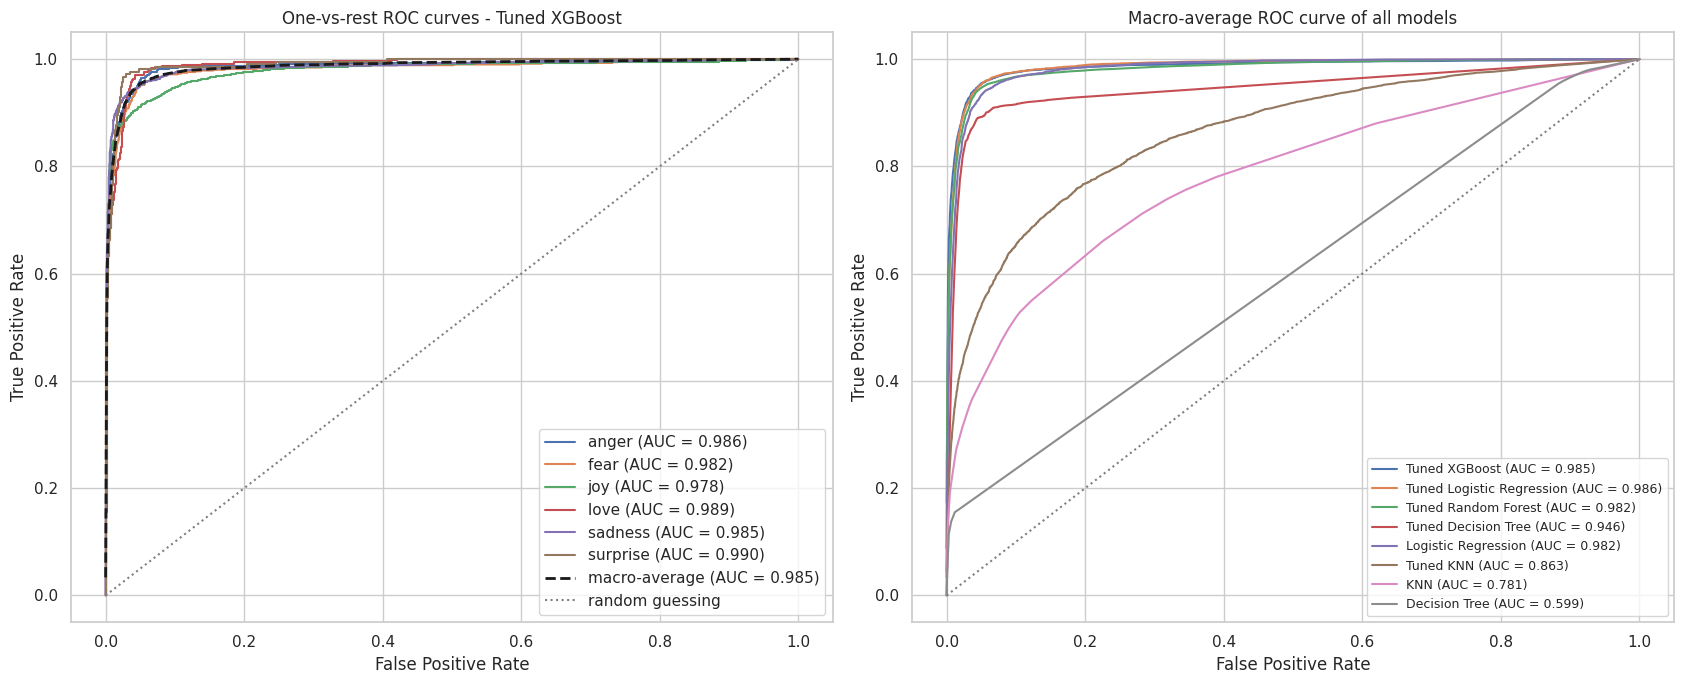

AUC SCORE - Tuned XGBoost


,AUC (one-vs-rest)
anger,0.9859
fear,0.9817
joy,0.9780
love,0.9886
sadness,0.9850
surprise,0.9905
macro-average,0.9849


In [34]:
y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))

def macro_roc(y_bin, proba):
    # Macro-average ROC curve: average the one-vs-rest TPR over a common FPR grid
    all_fpr = np.unique(np.concatenate([roc_curve(y_bin[:, i], proba[:, i])[0] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        f, t, _ = roc_curve(y_bin[:, i], proba[:, i])
        mean_tpr += np.interp(all_fpr, f, t)
    return all_fpr, mean_tpr / n_classes

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# (a) one-vs-rest ROC curve of every emotion for the selected model
class_auc = {}
for i, emo in enumerate(CLASS_NAMES):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], best_proba[:, i])
    class_auc[emo] = auc(fpr_i, tpr_i)
    axes[0].plot(fpr_i, tpr_i, label=f"{emo} (AUC = {class_auc[emo]:.3f})")
mf, mt = macro_roc(y_test_bin, best_proba)
axes[0].plot(mf, mt, "k--", linewidth=2, label=f"macro-average (AUC = {auc(mf, mt):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", linestyle=":", label="random guessing")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title(f"One-vs-rest ROC curves - {best_model_name}")
axes[0].legend(loc="lower right")

# (b) macro-average ROC curve of all models
for name in final_comparison["Model"]:
    f_m, t_m = macro_roc(y_test_bin, probabilities[name])
    axes[1].plot(f_m, t_m, label=f"{name} (AUC = {results[name]['ROC-AUC (OvR)']:.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Macro-average ROC curve of all models")
axes[1].legend(loc="lower right", fontsize=9)
save_fig("12_roc_curves")

auc_table = pd.DataFrame({"AUC (one-vs-rest)": class_auc})
auc_table.loc["macro-average"] = roc_auc_score(y_test, best_proba, multi_class="ovr", average="macro")
print("AUC SCORE -", best_model_name)
display(auc_table.round(4))

In [35]:
lowest_auc = min(class_auc, key=class_auc.get)
highest_auc = max(class_auc, key=class_auc.get)
say(f"Interpretation (ROC / AUC): the selected model {best_model_name} reaches a macro-average AUC of {auc_table.loc['macro-average', 'AUC (one-vs-rest)']:.3f}. "
    f"The emotion that is separated best from the others is '{highest_auc}' (AUC = {class_auc[highest_auc]:.3f}) and the hardest one is '{lowest_auc}' "
    f"(AUC = {class_auc[lowest_auc]:.3f}). An AUC close to 1 means that the model almost always gives a higher probability to a text of that emotion than to a text of another emotion, "
    f"even if the final decision (the class with the highest probability) is sometimes wrong. The curves that bend closer to the top-left corner belong to the better models.")

Interpretation (ROC / AUC): the selected model Tuned XGBoost reaches a macro-average AUC of 0.985. The emotion
that is separated best from the others is 'surprise' (AUC = 0.990) and the hardest one is 'joy' (AUC = 0.978).
An AUC close to 1 means that the model almost always gives a higher probability to a text of that emotion than
to a text of another emotion, even if the final decision (the class with the highest probability) is sometimes
wrong. The curves that bend closer to the top-left corner belong to the better models.


### Feature importance
For a text classifier the "features" are **words and word pairs** (TF-IDF terms). Three complementary views are used: the **Logistic Regression coefficients** (which words push a text towards each emotion), the **Random Forest importance** and the **XGBoost importance** (how much a word helps the trees to separate the emotions).

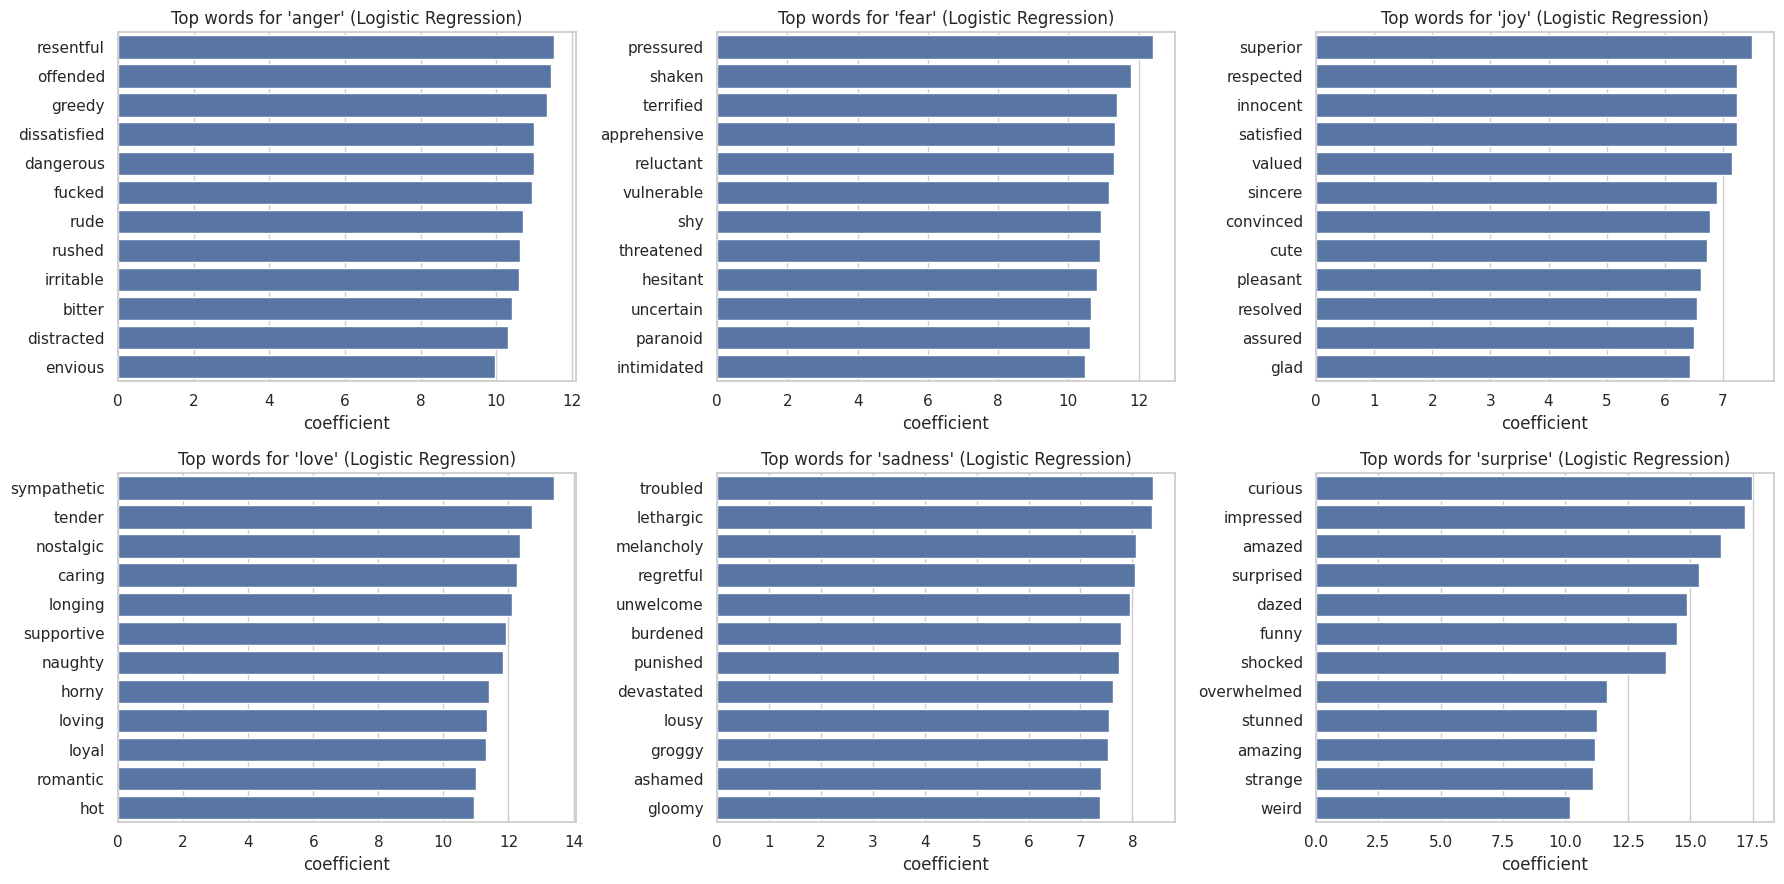

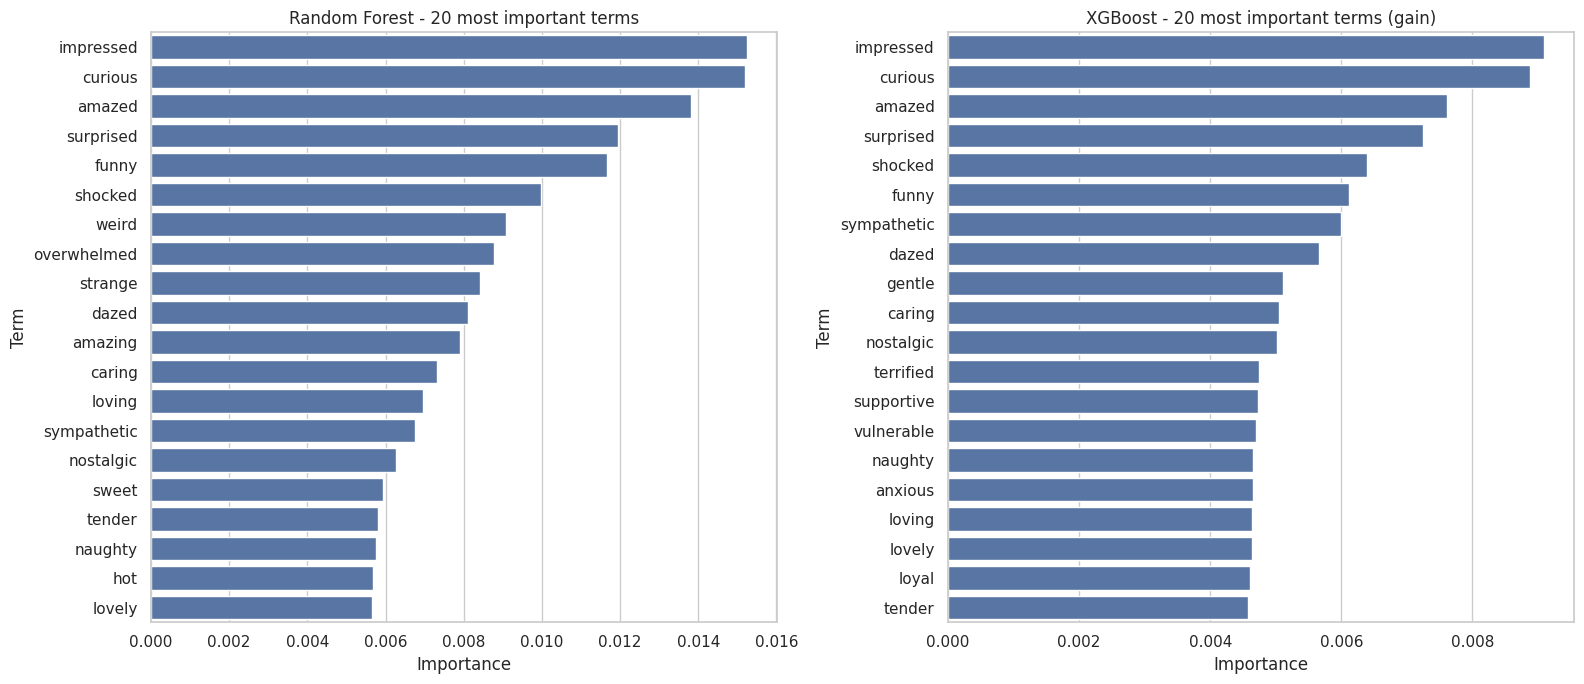

Top 10 terms - Random Forest : impressed, curious, amazed, surprised, funny, shocked, weird, overwhelmed, strange, dazed
Top 10 terms - XGBoost       : impressed, curious, amazed, surprised, shocked, funny, sympathetic, dazed, gentle, caring


In [36]:
# --- Logistic Regression: the words with the largest positive coefficient for every emotion ---
lr_best = models["Tuned Logistic Regression"]
lr_terms = np.array(lr_best.named_steps["tfidf"].get_feature_names_out())
lr_coef = lr_best.named_steps["clf"].coef_            # shape: (6 emotions, n terms)

lr_top = {}
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for i, (ax, emo) in enumerate(zip(axes.ravel(), CLASS_NAMES)):
    idx = np.argsort(lr_coef[i])[::-1][:12]
    lr_top[emo] = list(lr_terms[idx])
    sns.barplot(x=lr_coef[i][idx], y=lr_terms[idx], ax=ax)
    ax.set_title(f"Top words for '{emo}' (Logistic Regression)")
    ax.set_xlabel("coefficient")
save_fig("13_lr_top_words")

# --- Random Forest and XGBoost: global importance of the terms ---
def tree_importance(model_name, top_n=20):
    pipe = models[model_name]
    terms = np.array(pipe.named_steps["tfidf"].get_feature_names_out())
    imp = pipe.named_steps["clf"].feature_importances_
    idx = np.argsort(imp)[::-1][:top_n]
    return pd.DataFrame({"Term": terms[idx], "Importance": imp[idx]})

imp_rf = tree_importance("Tuned Random Forest")
imp_xgb = tree_importance("Tuned XGBoost")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=imp_rf, x="Importance", y="Term", ax=axes[0])
axes[0].set_title("Random Forest - 20 most important terms")
sns.barplot(data=imp_xgb, x="Importance", y="Term", ax=axes[1])
axes[1].set_title("XGBoost - 20 most important terms (gain)")
save_fig("14_tree_feature_importance")

print("Top 10 terms - Random Forest :", ", ".join(imp_rf["Term"].head(10)))
print("Top 10 terms - XGBoost       :", ", ".join(imp_xgb["Term"].head(10)))

In [37]:
say("Explanation (feature importance): the Logistic Regression coefficients show the vocabulary the model has learned for every emotion - "
    + "; ".join(f"{emo}: {', '.join(lr_top[emo][:5])}" for emo in CLASS_NAMES) + ". "
    f"The two tree ensembles rank the terms by how much they help to separate the emotions; the most important terms for Random Forest are "
    f"{', '.join(imp_rf['Term'].head(5))} and for XGBoost {', '.join(imp_xgb['Term'].head(5))}. "
    f"When the three views name similar words, the models have learned real emotional vocabulary rather than noise. "
    f"Words that appear in many emotions carry little weight, because TF-IDF down-weights them.")

Explanation (feature importance): the Logistic Regression coefficients show the vocabulary the model has
learned for every emotion - anger: resentful, offended, greedy, dissatisfied, dangerous; fear: pressured,
shaken, terrified, apprehensive, reluctant; joy: superior, respected, innocent, satisfied, valued; love:
sympathetic, tender, nostalgic, caring, longing; sadness: troubled, lethargic, melancholy, regretful,
unwelcome; surprise: curious, impressed, amazed, surprised, dazed. The two tree ensembles rank the terms by
how much they help to separate the emotions; the most important terms for Random Forest are impressed,
curious, amazed, surprised, funny and for XGBoost impressed, curious, amazed, surprised, shocked. When the
three views name similar words, the models have learned real emotional vocabulary rather than noise. Words
that appear in many emotions carry little weight, because TF-IDF down-weights them.


In [38]:
# Error analysis: look at real texts that the selected model got wrong
test_view = pd.DataFrame({"Text": X_test.values,
                          "True emotion": [CLASS_NAMES[i] for i in np.asarray(y_test)],
                          "Predicted": [CLASS_NAMES[i] for i in best_predictions],
                          "Confidence": best_proba.max(axis=1).round(3)})
wrong = test_view[test_view["True emotion"] != test_view["Predicted"]]
print(f"{len(wrong)} of {len(test_view)} test texts are misclassified ({100 * len(wrong) / len(test_view):.1f}%). A random sample:")
with pd.option_context("display.max_colwidth", 110):
    display(wrong.sample(min(10, len(wrong)), random_state=SEED).reset_index(drop=True))

665 of 5970 test texts are misclassified (11.1%). A random sample:


,Text,True emotion,Predicted,Confidence
0,i had climbed on a cherry tree alone and there was a thick caterpillar beside my fingers i feel disgusted ...,fear,anger,0.881
1,im feeling nervous but since it wasnt sore to touch to stretch or to use the muscles i felt assured it was...,fear,joy,0.504
2,i also feel extremely blessed to be marrying into such a loving family,joy,love,0.994
3,i just love the colors and the way the yarns feel i also love supporting small businesses and it allows me...,joy,love,0.842
4,i felt like id developed feelings for this guy thus explaining why id even follow this guy like a faithful...,joy,love,0.979
5,i just don t like to smile don t feel like talking and i don t want to be considerate,joy,love,0.576
6,i cannot in good conscience encourage my young kids read stuff from someone i feel is so vile no matter ho...,anger,joy,0.580
7,i feel so hopeless and strange and all i really want is to actually disappear,sadness,fear,0.686
8,i never knew i could be so weak i couldnt even fight what i was feeling i knew i hated to feel that way ye...,anger,sadness,0.903
9,i bought into what the world had told me would fill this emptiness but all it did was leave me lonely feel...,fear,sadness,0.527


---
# WEEK 4 — Interpretation, Documentation & Deployment Insight

## 4.1 Final model selection justification

In [39]:
# Auto-generated, data-driven justification of the final model (selection = cross-validation, NOT the test set)
ranked = cv_pool
winner, runner = ranked.iloc[0], ranked.iloc[1]
base_f1 = baseline_results.iloc[0]["F1 (macro)"]
improvement = 100 * (winner["F1 (macro)"] - base_f1) / base_f1

print("FINAL MODEL SELECTED:", winner["Model"])
print("=" * 70)
print(f"CV macro-F1 : {winner['CV F1 (macro)']:.3f}   (runner-up {runner['Model']}: {runner['CV F1 (macro)']:.3f})  <- used for selection")
print("Final evaluation on the untouched test set:")
print(f"  Accuracy          : {winner['Accuracy']:.4f}")
print(f"  Precision (macro) : {winner['Precision (macro)']:.4f}")
print(f"  Recall (macro)    : {winner['Recall (macro)']:.4f}")
print(f"  F1 (macro)        : {winner['F1 (macro)']:.4f}")
print(f"  ROC-AUC (OvR)     : {winner['ROC-AUC (OvR)']:.4f}")
print(f"Change vs best baseline ({baseline_results.iloc[0]['Model']}) on the test set: {improvement:+.1f}% macro-F1")
print()

gap_runner = 100 * (winner["CV F1 (macro)"] - runner["CV F1 (macro)"]) / runner["CV F1 (macro)"]
name = winner["Model"]
if "Logistic" in name:
    why_type = ("A linear model on TF-IDF features is fast, needs little memory, handles thousands of sparse word features well, gives calibrated class "
                "probabilities and is fully interpretable (every word has a coefficient per emotion) - an advantage when the results must be explained to a business team.")
elif "Forest" in name or "XGBoost" in name:
    why_type = ("Tree ensembles capture non-linear effects and word interactions without feature scaling and provide feature-importance estimates; "
                "tuning with cross-validation keeps their variance under control.")
elif "KNN" in name:
    why_type = ("KNN predicts from the most similar texts, which is easy to explain, but it is slow at prediction time and sensitive to the vector representation.")
else:
    why_type = ("A decision tree is easy to visualise as a set of word rules, but single trees are less stable than ensembles.")
winner_is_baseline = name in BASELINE_MODELS
vs_base = (f"It changes the macro-F1 of the best untuned baseline ({baseline_results.iloc[0]['Model']}) by {improvement:+.1f}% on the test set (positive = better)."
           if not winner_is_baseline else
           "It is itself one of the Week 1 baselines: more complex models did not beat it in cross-validation, so the simpler model is preferred (principle of parsimony).")
say(f"Justification: {name} was selected because it achieved the highest cross-validated macro-F1 ({winner['CV F1 (macro)']:.3f}) among the {len(ranked)} candidates; "
    f"it is {gap_runner:.1f}% better in CV macro-F1 than the runner-up ({runner['Model']}). The test set was NOT used for selection. "
    f"On the {len(y_test)} untouched test texts it reaches Accuracy = {winner['Accuracy']:.4f}, macro-F1 = {winner['F1 (macro)']:.4f} and a macro-average AUC of {winner['ROC-AUC (OvR)']:.4f}. "
    f"{vs_base} {why_type}")
final_model = models[best_model_name]

FINAL MODEL SELECTED: Tuned XGBoost
CV macro-F1 : 0.858   (runner-up Tuned Logistic Regression: 0.856)  <- used for selection
Final evaluation on the untouched test set:
  Accuracy          : 0.8886
  Precision (macro) : 0.8467
  Recall (macro)    : 0.8696
  F1 (macro)        : 0.8568
  ROC-AUC (OvR)     : 0.9849
Change vs best baseline (Logistic Regression) on the test set: +12.5% macro-F1

Justification: Tuned XGBoost was selected because it achieved the highest cross-validated macro-F1 (0.858)
among the 8 candidates; it is 0.2% better in CV macro-F1 than the runner-up (Tuned Logistic Regression). The
test set was NOT used for selection. On the 5970 untouched test texts it reaches Accuracy = 0.8886, macro-F1 =
0.8568 and a macro-average AUC of 0.9849. It changes the macro-F1 of the best untuned baseline (Logistic
Regression) by +12.5% on the test set (positive = better). Tree ensembles capture non-linear effects and word
interactions without feature scaling and provide feature-import

## 4.2 Feature importance explanation

In [40]:
say("Explanation: the importance charts of Week 2 show which words (and two-word phrases) push a sentence towards each emotion. "
    "For the Logistic Regression model the strongest words are - "
    + "; ".join(f"{emo}: {', '.join(lr_top[emo][:4])}" for emo in CLASS_NAMES) + ". "
    "These words can be compared with the chi-square analysis of Week 1 and with the Random Forest and XGBoost importances: terms that appear in several of these views "
    "are the most trustworthy signals, because they show that the models have learned real emotional vocabulary rather than noise. "
    "Filler words that occur in all emotions receive low weights, because TF-IDF and the models treat them as uninformative.")

Explanation: the importance charts of Week 2 show which words (and two-word phrases) push a sentence towards
each emotion. For the Logistic Regression model the strongest words are - anger: resentful, offended, greedy,
dissatisfied; fear: pressured, shaken, terrified, apprehensive; joy: superior, respected, innocent, satisfied;
love: sympathetic, tender, nostalgic, caring; sadness: troubled, lethargic, melancholy, regretful; surprise:
curious, impressed, amazed, surprised. These words can be compared with the chi-square analysis of Week 1 and
with the Random Forest and XGBoost importances: terms that appear in several of these views are the most
trustworthy signals, because they show that the models have learned real emotional vocabulary rather than
noise. Filler words that occur in all emotions receive low weights, because TF-IDF and the models treat them
as uninformative.


## 4.3 Business insights

,precision,recall,f1-score,support
anger,0.898,0.852,0.875,810.0
fear,0.850,0.860,0.855,707.0
joy,0.906,0.900,0.903,2019.0
love,0.754,0.882,0.813,484.0
sadness,0.948,0.916,0.932,1737.0
surprise,0.723,0.808,0.763,213.0


,Confidence threshold,Share of texts handled automatically,Accuracy on these texts
0,0.30,0.998,0.890
1,0.35,0.989,0.896
2,0.40,0.974,0.903
3,0.45,0.959,0.911
4,0.50,0.940,0.917
5,0.55,0.914,0.927
6,0.60,0.886,0.934
7,0.65,0.853,0.943
8,0.70,0.820,0.950
9,0.75,0.769,0.957


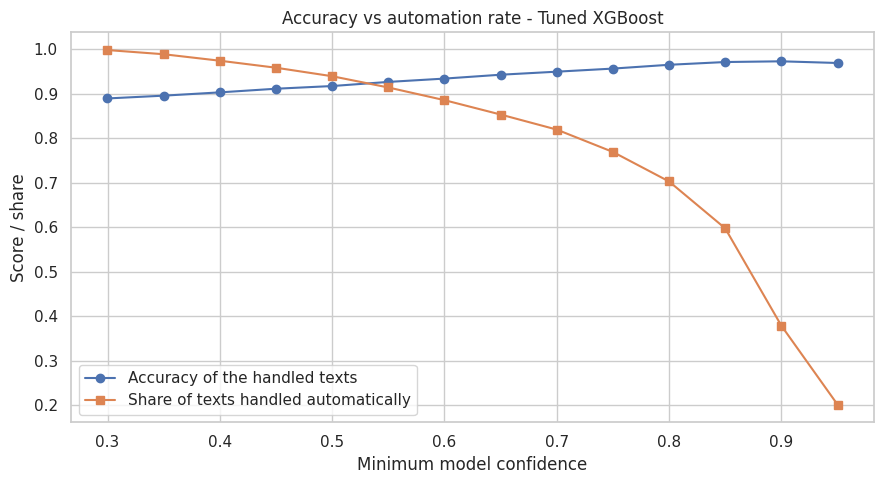

In [41]:
# How reliable is the model for every emotion?  (final model, test set)
final_report = pd.DataFrame(classification_report(y_test, predictions[best_model_name], target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T.loc[CLASS_NAMES]
display(final_report[["precision", "recall", "f1-score", "support"]].round(3))

# Confidence analysis: what if the system only acts automatically when the model is sure enough?
confidence = best_proba.max(axis=1)
is_correct = (best_predictions == np.asarray(y_test))
rows = []
for t in np.arange(0.30, 0.96, 0.05):
    mask = confidence >= t
    rows.append({"Confidence threshold": round(t, 2), "Share of texts handled automatically": mask.mean(),
                 "Accuracy on these texts": is_correct[mask].mean() if mask.any() else np.nan})
conf_table = pd.DataFrame(rows)
display(conf_table.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(conf_table["Confidence threshold"], conf_table["Accuracy on these texts"], marker="o", label="Accuracy of the handled texts")
ax.plot(conf_table["Confidence threshold"], conf_table["Share of texts handled automatically"], marker="s", label="Share of texts handled automatically")
ax.set_xlabel("Minimum model confidence")
ax.set_ylabel("Score / share")
ax.set_title(f"Accuracy vs automation rate - {best_model_name}")
ax.legend()
save_fig("15_confidence_vs_accuracy")

In [42]:
# Auto-generated business insights
best_cls = final_report["f1-score"].idxmax()
worst_cls = final_report["f1-score"].idxmin()
top_conf = confusions.iloc[0]
ok = conf_table[conf_table["Accuracy on these texts"] >= 0.95]
if len(ok):
    thr = ok.iloc[0]
    threshold_text = (f"If the system only acts automatically when its confidence is at least {thr['Confidence threshold']:.2f}, it handles "
                      f"{100 * thr['Share of texts handled automatically']:.0f}% of the texts with an accuracy of {100 * thr['Accuracy on these texts']:.0f}%, "
                      f"and the remaining texts can be sent to a human reviewer.")
else:
    threshold_text = ("Even at a high confidence threshold the accuracy of the automatically handled texts stays below 95%, so a human check is "
                      "recommended for important decisions.")

print("BUSINESS INSIGHTS")
print("-" * 70)
say(f"1. The final model recognises '{best_cls}' best (F1 = {final_report.loc[best_cls, 'f1-score']:.2f}) and '{worst_cls}' worst "
    f"(F1 = {final_report.loc[worst_cls, 'f1-score']:.2f}). A business should therefore trust the predictions for '{best_cls}' most and double-check '{worst_cls}'.")
say(f"2. The most frequent mix-up is '{top_conf['True emotion']}' predicted as '{top_conf['Predicted as']}' "
    f"({top_conf['Texts']} texts, {top_conf['Share of the true class (%)']}% of all '{top_conf['True emotion']}' texts). "
    f"Because these two emotions are often confused, reports should show the second most likely emotion as well or treat the pair with care.")
say(f"3. Triage use case: {threshold_text}")
level = "a high" if winner["Accuracy"] >= 0.85 else "only a moderate"
say(f"4. The final model reaches an accuracy of {100 * winner['Accuracy']:.1f}% and a macro-F1 of {winner['F1 (macro)']:.2f}, which is {level} level of reliability. "
    f"It is best suited to monitoring trends, tagging feedback and prioritising messages; decisions about a single person should always include a human review.")
say("5. The model should be re-checked regularly on fresh data from the real channel (reviews, chat, e-mail), because the wording and the emotions of customers change over time.")

BUSINESS INSIGHTS
----------------------------------------------------------------------
1. The final model recognises 'sadness' best (F1 = 0.93) and 'surprise' worst (F1 = 0.76). A business should
therefore trust the predictions for 'sadness' most and double-check 'surprise'.
2. The most frequent mix-up is 'joy' predicted as 'love' (109 texts, 5.4% of all 'joy' texts). Because these
two emotions are often confused, reports should show the second most likely emotion as well or treat the pair
with care.
3. Triage use case: If the system only acts automatically when its confidence is at least 0.75, it handles 77%
of the texts with an accuracy of 96%, and the remaining texts can be sent to a human reviewer.
4. The final model reaches an accuracy of 88.9% and a macro-F1 of 0.86, which is a high level of reliability.
It is best suited to monitoring trends, tagging feedback and prioritising messages; decisions about a single
person should always include a human review.
5. The model should be

## 4.4 Model limitations

1. **Bag-of-words view of language:** TF-IDF ignores word order and context, so negation ("not happy"), sarcasm and mixed feelings are easily mis-classified.
2. **Single, sometimes ambiguous labels:** every sentence has exactly one emotion label although people often feel several emotions at once, so some labels are ambiguous and the model cannot reach a perfect score.
3. **Class imbalance:** the rare emotions have far fewer examples, so their predictions are less reliable even with class weights.
4. **Limited domain and language:** the data contains short English sentences of one style; the model will perform worse on other languages, long documents, slang, emojis or other domains (e.g. formal customer e-mails).
5. **No neutral class:** every text is forced into one of the six emotions, even if it contains no emotion at all.
6. **Fixed vocabulary:** words that were not in the training data (new slang, spelling mistakes) are ignored by the TF-IDF vectoriser.

## 4.5 Future improvements

1. Use **pre-trained language models** (BERT, DistilBERT, RoBERTa) or word embeddings (Word2Vec, GloVe) that understand context, negation and word order.
2. Add a **neutral** class and move to **multi-label** emotion detection (several emotions per text).
3. Collect more examples of the rare emotions or use data augmentation (back-translation, synonym replacement) and test SMOTE on dense embeddings.
4. Test LightGBM / CatBoost and stacking ensembles, and calibrate the predicted probabilities.
5. Use **SHAP** or LIME for per-prediction explanations.
6. Evaluate on text from the real business channel and monitor the model after deployment.

## 4.6 Save the final model and a prediction function
The selected pipeline (TF-IDF vectoriser + classifier) is saved together with the label names, so it can be loaded later and applied to new text.

In [43]:
# ---------------------------------------------------------------
# Save the final model (selected by cross-validation)
# ---------------------------------------------------------------
bundle = {
    "model": final_model,
    "model_name": best_model_name,
    "classes": CLASS_NAMES,
    "metrics": {"Accuracy": float(winner["Accuracy"]), "F1 (macro)": float(winner["F1 (macro)"]),
                "ROC-AUC (OvR)": float(winner["ROC-AUC (OvR)"])},
}
joblib.dump(bundle, "emotion_model.joblib")
print("Saved final model:", best_model_name, "-> emotion_model.joblib")

# Sanity check: the reloaded model must reproduce the notebook predictions
reloaded = joblib.load("emotion_model.joblib")
check = reloaded["model"].predict_proba(X_test.iloc[:5])
print("Reloaded-model prediction check (first 5 test texts):")
print(np.round(check.max(axis=1), 3), "vs", np.round(best_proba[:5].max(axis=1), 3))
assert np.allclose(check, best_proba[:5], atol=1e-6), "Reloaded model does not match!"

Saved final model: Tuned XGBoost -> emotion_model.joblib
Reloaded-model prediction check (first 5 test texts):
[0.893 0.642 0.955 0.784 0.895] vs [0.893 0.642 0.955 0.784 0.895]


In [44]:
# A small helper that predicts the emotion of any new text (works with the saved model as well)
def predict_emotion(texts, model=None, classes=None, top_k=2):
    model = model if model is not None else reloaded["model"]
    classes = classes if classes is not None else reloaded["classes"]
    if isinstance(texts, str):
        texts = [texts]
    proba = model.predict_proba(pd.Series(texts))
    rows = []
    for text, p in zip(texts, proba):
        order = np.argsort(p)[::-1][:top_k]
        rows.append({"Text": text, "Predicted emotion": classes[order[0]], "Confidence": round(float(p[order[0]]), 3),
                     "Next most likely": ", ".join(f"{classes[k]} ({p[k]:.2f})" for k in order[1:])})
    return pd.DataFrame(rows)

examples = [
    "i feel so happy and grateful for everything my family did for me today",
    "i am terrified that something terrible is going to happen tonight",
    "i feel so angry and annoyed that nobody listens to me",
    "i feel lonely and hopeless since i lost my job",
    "i am amazed and shocked by this unexpected news",
    "i feel so much love and affection for my little sister",
]
with pd.option_context("display.max_colwidth", 90):
    display(predict_emotion(examples))

,Text,Predicted emotion,Confidence,Next most likely
0,i feel so happy and grateful for everything my family did for me today,joy,0.698,sadness (0.17)
1,i am terrified that something terrible is going to happen tonight,fear,0.506,sadness (0.44)
2,i feel so angry and annoyed that nobody listens to me,anger,0.995,joy (0.00)
3,i feel lonely and hopeless since i lost my job,sadness,0.994,joy (0.00)
4,i am amazed and shocked by this unexpected news,surprise,1.000,sadness (0.00)
5,i feel so much love and affection for my little sister,joy,0.408,sadness (0.31)


## 4.7 Conclusion

In [45]:
print("CONCLUSION")
print("=" * 70)
say("The Emotion Detection project applied machine learning to classify short English texts into six emotions: sadness, joy, love, anger, fear and surprise. "
    "After exploratory analysis (missing values, duplicates, outliers, distributions, word associations), the data was encoded with TF-IDF and split 70:30 (stratified). "
    "Logistic Regression, Decision Tree and KNN were used as baselines, followed by Random Forest and XGBoost, all tuned with "
    "GridSearchCV and compared with 5-fold stratified cross-validation, ROC / AUC analysis, class-weight based imbalance handling and feature-importance analysis.")
print()
say(f"The selected model, {winner['Model']}, achieved an accuracy of {winner['Accuracy']:.4f} ({winner['Accuracy'] * 100:.2f}%), a macro-F1 of {winner['F1 (macro)']:.4f} "
    f"and a macro-average AUC of {winner['ROC-AUC (OvR)']:.4f} on {len(y_test)} unseen test texts "
    f"({'it is one of the baseline models; the tuned ensembles gave no meaningful improvement' if winner_is_baseline else f'a {improvement:+.1f}% change in macro-F1 compared with the best untuned baseline'}). "
    f"The words that drive the predictions are listed in the feature-importance analysis; the hardest emotion to recognise is '{worst_cls}'.")
print()
say("The business analysis showed which emotions can be trusted, which are confused with each other and how a confidence threshold can split the "
    "work between automatic handling and human review. The saved model and the prediction function illustrate how the model can be reused on new text. "
    "Final deliverables: this Jupyter notebook (.ipynb), a 6-8 page technical report and a 10-12 minute presentation.")

CONCLUSION
The Emotion Detection project applied machine learning to classify short English texts into six emotions:
sadness, joy, love, anger, fear and surprise. After exploratory analysis (missing values, duplicates,
outliers, distributions, word associations), the data was encoded with TF-IDF and split 70:30 (stratified).
Logistic Regression, Decision Tree and KNN were used as baselines, followed by Random Forest and XGBoost, all
tuned with GridSearchCV and compared with 5-fold stratified cross-validation, ROC / AUC analysis, class-weight
based imbalance handling and feature-importance analysis.

The selected model, Tuned XGBoost, achieved an accuracy of 0.8886 (88.86%), a macro-F1 of 0.8568 and a macro-
average AUC of 0.9849 on 5970 unseen test texts (a +12.5% change in macro-F1 compared with the best untuned
baseline). The words that drive the predictions are listed in the feature-importance analysis; the hardest
emotion to recognise is 'surprise'.

The business analysis showed wh